In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings


from sklearn.discriminant_analysis import LinearDiscriminantAnalysis as LDA
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge, Lasso, ElasticNet
from sklearn.linear_model import RidgeCV, LassoCV,ElasticNetCV
from sklearn.model_selection import RepeatedKFold
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import KFold, LeaveOneOut, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegressionCV
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold


# Secção 2

In [5]:
warnings.filterwarnings("ignore")  # Ignorar avisos para uma saída mais limpa
# Configuração visual para os gráficos
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

# 1. Carregamento e Inspeção Inicial
df = pd.read_csv('dataset_grupo_01.csv')

print("--- Dimensões do Dataset ---")
print(f"Linhas: {df.shape[0]} | Colunas: {df.shape[1]}")

print("\n--- Primeiras Instâncias ---")
display(df.head())

print("\n--- Tipos de Dados e Valores em Falta ---")
df.info()

print("\n--- Verificação de Valores Nulos por Coluna ---")
print(df.isnull().sum()[df.isnull().sum() > 0])

--- Dimensões do Dataset ---
Linhas: 2000 | Colunas: 35

--- Primeiras Instâncias ---


,age_level,gender,bmi_level,smoking,age,age_normalized,bmi,HbA1c_level,cholesterol,sleep_hours,...,hdl,ldl,education_level,employment_status,systolic_index,calcium_baseline,plasma_value,ldl_alternative,target_regression,target_class
0,Mature,Male,Obese,Former,63,0.701149,34.70,5.415916,235.000000,9.100000,...,88.000000,125.000000,Primary,Unemployed,121.000000,9.42,1.288610,94.000000,70.0,N
1,Mature,Male,Obese,Never,59,0.655172,30.07,6.100000,225.628141,6.816071,...,64.268197,130.545353,Primary,Employed,133.613102,9.42,1.113728,153.000000,130.0,N
2,Middle,Female,Obese,Never,44,0.482758,31.70,6.804854,266.000000,9.800000,...,46.000000,158.000000,Primary,Employed,106.000000,9.42,1.193225,134.453901,92.0,DI_HY
3,Middle,Female,Overweight,Former,42,0.459770,28.50,5.405910,252.000000,5.000000,...,88.000000,90.000000,Secondary,Retired,96.000000,9.42,1.169763,101.000000,117.0,N
4,Mature,Female,Normal,Never,61,0.678161,23.38,6.000000,231.381443,6.968389,...,64.248021,130.816183,Tertiary,Retired,133.725594,9.42,1.378711,171.000000,145.0,N



--- Tipos de Dados e Valores em Falta ---
<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 35 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   age_level             2000 non-null   str    
 1   gender                2000 non-null   str    
 2   bmi_level             2000 non-null   str    
 3   smoking               2000 non-null   str    
 4   age                   2000 non-null   int64  
 5   age_normalized        2000 non-null   float64
 6   bmi                   2000 non-null   float64
 7   HbA1c_level           2000 non-null   float64
 8   cholesterol           2000 non-null   float64
 9   sleep_hours           2000 non-null   float64
 10  triglycerides         2000 non-null   float64
 11  physical_activity     2000 non-null   str    
 12  family_history        2000 non-null   str    
 13  stress_level          2000 non-null   str    
 14  low_hdl_cholesterol   2000 non-null   st

--- Estatísticas Descritivas (Variáveis Numéricas) ---


,age,age_normalized,bmi,HbA1c_level,cholesterol,sleep_hours,triglycerides,blood_pressure,crp_level,homocysteine_level,...,alcohol_intake,salt_intake,heart_rate,hdl,ldl,systolic_index,calcium_baseline,plasma_value,ldl_alternative,target_regression
count,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,...,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.00,2000.000000,2000.000000,2000.000000
mean,49.817500,0.549626,27.360674,5.823790,223.647108,6.941153,178.811071,149.687674,7.483729,12.453406,...,15.193352,8.544985,74.730287,64.426663,129.432779,134.426598,9.42,1.253070,129.432779,133.718000
std,21.924086,0.252001,6.883579,0.928032,34.915456,1.415719,66.089529,3.626313,0.882769,0.844962,...,6.873160,2.918042,11.537448,15.704977,27.339069,20.678479,0.00,0.148442,27.339069,36.750902
min,2.000000,0.000000,13.750000,3.500000,150.000000,4.000000,50.000000,121.000000,0.467803,5.309536,...,0.000000,2.000000,50.000000,30.000000,70.000000,90.000000,9.42,0.773790,70.000000,70.000000
25%,31.000000,0.333333,22.200000,5.374129,201.000000,6.200000,131.750000,148.625000,7.294863,12.287763,...,12.275000,7.375000,70.000000,56.000000,117.000000,126.000000,9.42,1.151398,117.000000,100.000000
50%,50.000000,0.551724,27.320000,5.494662,224.842938,6.982952,179.000000,149.587719,7.458483,12.504625,...,15.027543,8.477600,74.487247,64.650655,129.983051,134.176874,9.42,1.255863,129.983051,139.000000
75%,68.000000,0.758620,32.402500,6.750000,242.000000,7.700000,243.026316,150.654054,7.767442,12.681166,...,18.700000,10.000000,79.000000,71.000000,141.000000,144.000000,9.42,1.351915,141.000000,160.000000
max,89.000000,1.000000,68.530000,9.000000,299.000000,10.000000,388.000000,176.000000,14.922016,19.959139,...,30.000000,15.000000,99.000000,99.000000,189.000000,179.000000,9.42,1.714795,189.000000,280.000000



--- Estatísticas Descritivas (Variáveis Categóricas) ---


,age_level,gender,bmi_level,smoking,physical_activity,family_history,stress_level,low_hdl_cholesterol,high_ldl_cholesterol,sugar_consumption,education_level,employment_status,target_class
count,2000,2000,2000,2000,2000,2000,2000,2000,2000,2000,2000,2000,2000
unique,4,2,4,3,3,2,3,2,2,3,3,3,3
top,Mature,Female,Obese,Never,High,No,High,No,Yes,Low,Tertiary,Retired,N
freq,620,1055,690,925,879,1132,763,1626,1013,887,740,688,863


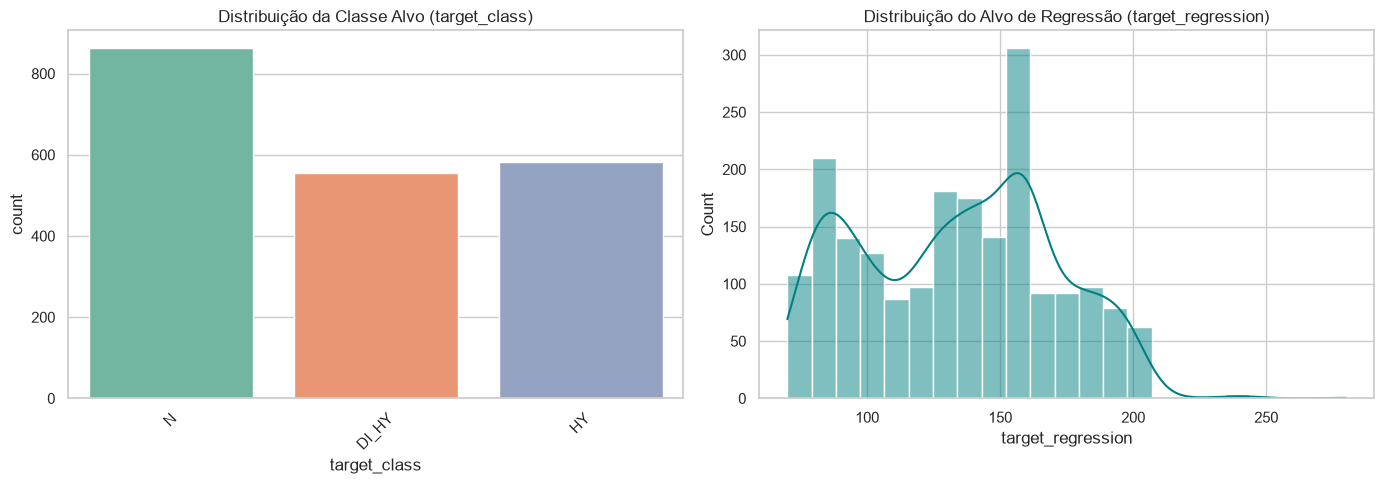

In [61]:
warnings.filterwarnings("ignore")  # Ignorar avisos para uma saída mais limpa
# Estatísticas descritivas para variáveis numéricas
print("--- Estatísticas Descritivas (Variáveis Numéricas) ---")
display(df.describe())

# Estatísticas descritivas para variáveis categóricas
print("\n--- Estatísticas Descritivas (Variáveis Categóricas) ---")
display(df.describe(include=['O']))

# Visualização da Distribuição das Variáveis Alvo
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# target_class (Categórica)
sns.countplot(data=df, x='target_class', ax=axes[0], palette='Set2')
axes[0].set_title('Distribuição da Classe Alvo (target_class)')
axes[0].tick_params(axis='x', rotation=45)

# target_regression (Contínua)
sns.histplot(data=df, x='target_regression', kde=True, ax=axes[1], color='teal')
axes[1].set_title('Distribuição do Alvo de Regressão (target_regression)')

plt.tight_layout()
plt.show()

--- A gerar histogramas para as variáveis selecionadas ---


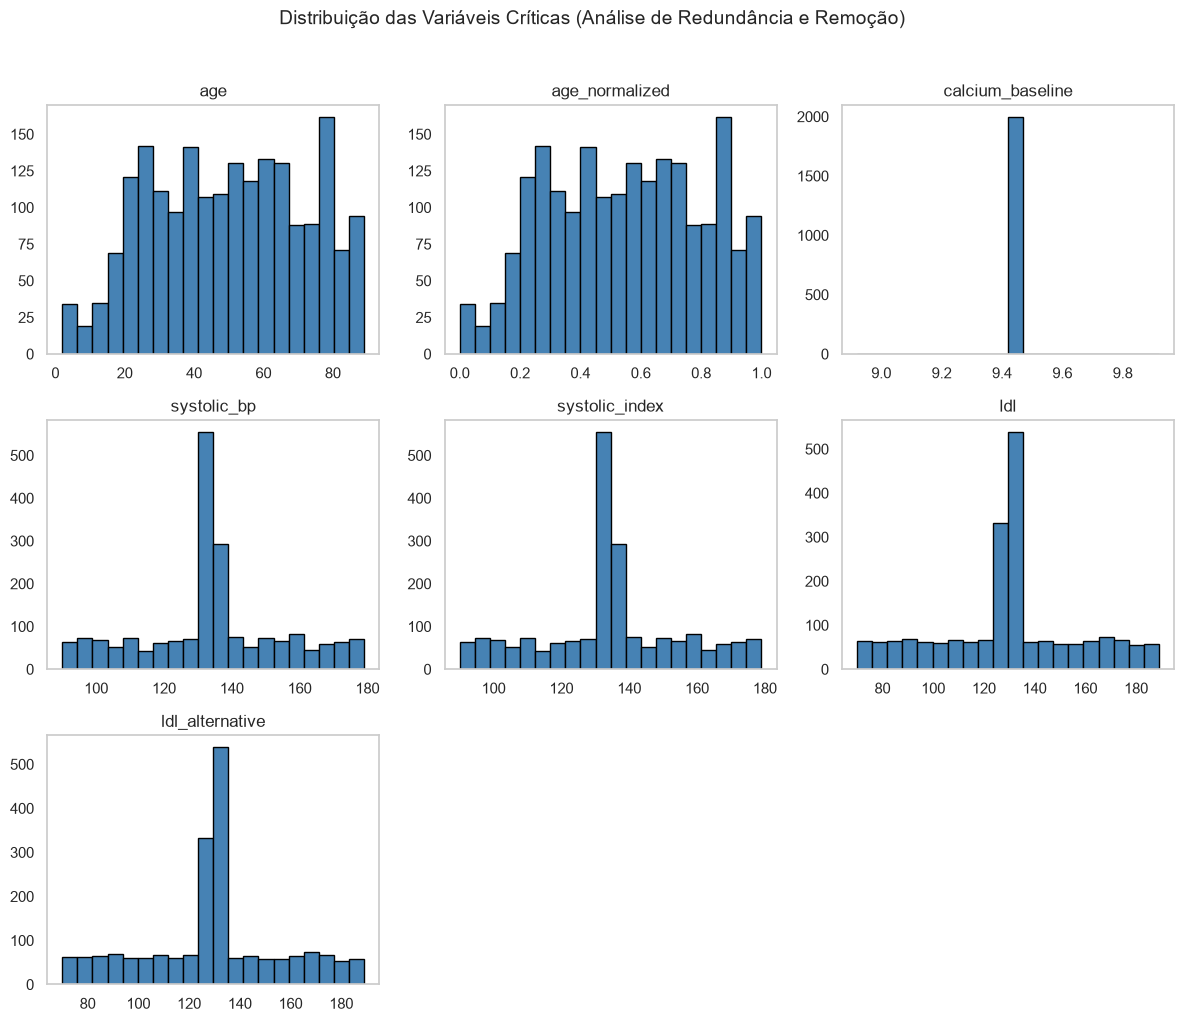

In [62]:
warnings.filterwarnings('ignore')  # Ignorar avisos para uma saída mais limpa

# 1. Análise Univariada - Histogramas apenas para as variáveis-chave a remover ou destacar
cols_to_plot = [
    'age',
    'age_normalized',
    'calcium_baseline',
    'systolic_bp',
    'systolic_index',
    'ldl',
    'ldl_alternative',
]

# Filtrar apenas as colunas que realmente existem no DataFrame para evitar erros
valid_cols = [col for col in cols_to_plot if col in df.columns]

print('--- A gerar histogramas para as variáveis selecionadas ---')
df[valid_cols].hist(
    bins=20, figsize=(12, 10), color='steelblue', edgecolor='black', grid=False
)
plt.suptitle(
    'Distribuição das Variáveis Críticas (Análise de Redundância e Remoção)',
    fontsize=14,
    y=1.02,
)
plt.tight_layout()
plt.show()

--- Correlação com 'target_regression' ---
target_regression     1.000000
crp_level             0.035336
ldl                   0.033595
plasma_value          0.028460
age                   0.028338
age_normalized        0.028338
blood_pressure        0.024940
alcohol_intake        0.018099
systolic_index        0.007601
systolic_bp           0.007601
hdl                   0.002775
ldl_alternative       0.002434
bmi                   0.000205
heart_rate           -0.003104
cholesterol          -0.009216
HbA1c_level          -0.012542
triglycerides        -0.019800
homocysteine_level   -0.020534
salt_intake          -0.020784
diastolic_bp         -0.040998
sleep_hours          -0.049979
calcium_baseline           NaN
Name: target_regression, dtype: float64


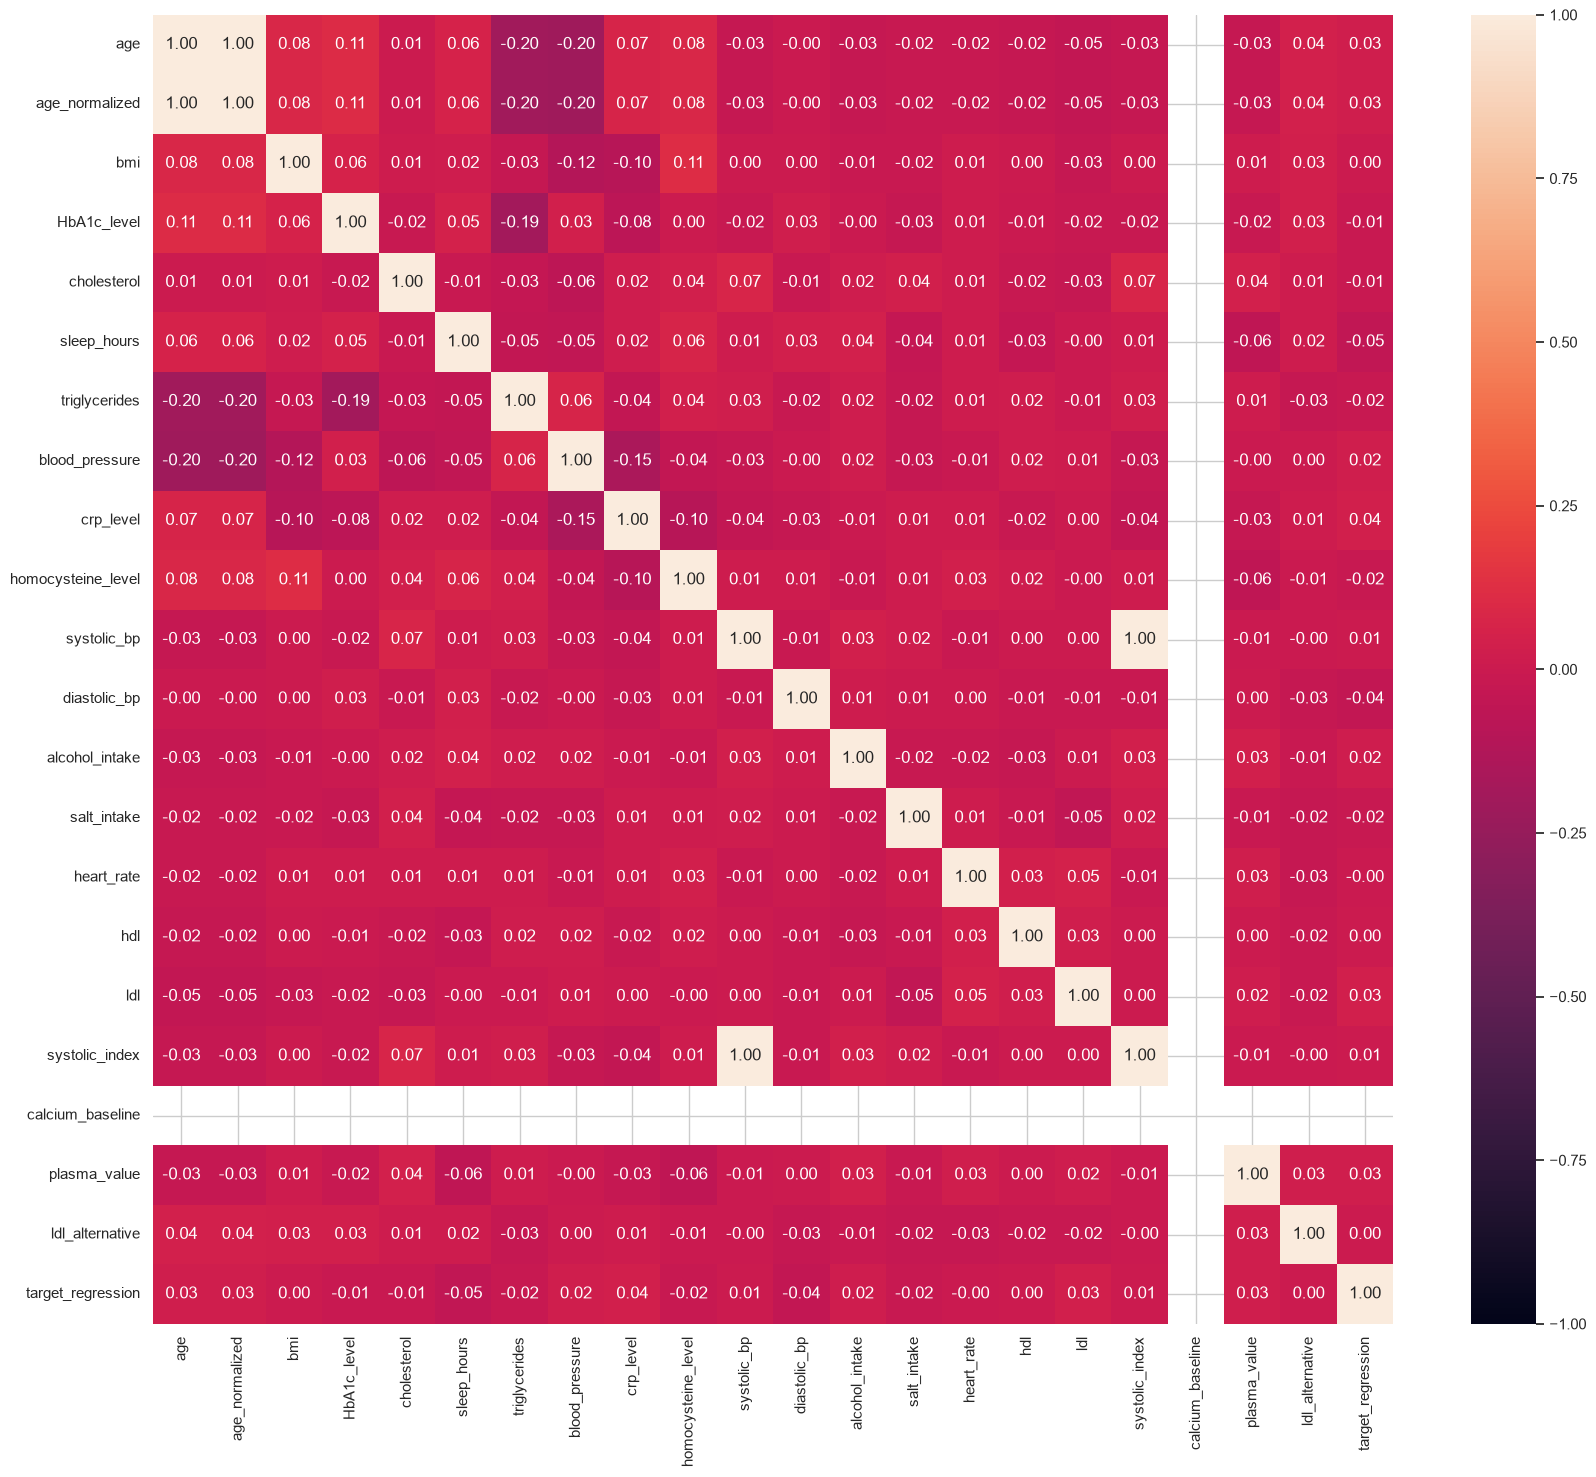


--- Variância das Variáveis Numéricas (Deteção de Constantes) ---
calcium_baseline    0.0
dtype: float64

--- Contagem de Valores Únicos (Variáveis Categóricas) ---
[age_level] -> 4 valores únicos: <StringArray>
['Mature', 'Middle', 'Young', 'Senior']
Length: 4, dtype: str
[gender] -> 2 valores únicos: <StringArray>
['Male', 'Female']
Length: 2, dtype: str
[bmi_level] -> 4 valores únicos: <StringArray>
['Obese', 'Overweight', 'Normal', 'Underweight']
Length: 4, dtype: str
[smoking] -> 3 valores únicos: <StringArray>
['Former', 'Never', 'Current']
Length: 3, dtype: str
[physical_activity] -> 3 valores únicos: <StringArray>
['High', 'Moderate', 'Low']
Length: 3, dtype: str
[family_history] -> 2 valores únicos: <StringArray>
['No', 'Yes']
Length: 2, dtype: str
[stress_level] -> 3 valores únicos: <StringArray>
['Low', 'Medium', 'High']
Length: 3, dtype: str
[low_hdl_cholesterol] -> 2 valores únicos: <StringArray>
['No', 'Yes']
Length: 2, dtype: str
[high_ldl_cholesterol] -> 2 valores únic

In [63]:
warnings.filterwarnings("ignore")  # Ignorar avisos para uma saída mais limpa
# 3. Análise Bivariada e Identificação de Características

# Correlação linear com o alvo de regressão (target_regression)
print("--- Correlação com 'target_regression' ---")
num_cols = df.select_dtypes(include=[np.number]).columns
corr_matrix = df[num_cols].corr()
if 'target_regression' in corr_matrix.columns:
    print(corr_matrix['target_regression'].sort_values(ascending=False))

# Heatmap da Matriz de Correlação Geral
plt.figure(figsize=(20,17))
sns.heatmap(corr_matrix, vmin=-1, vmax=1, annot=True, fmt='.2f') 
plt.show()

# Deteção de Variáveis Constantes (Variância igual a 0 ou muito próxima de 0)
print("\n--- Variância das Variáveis Numéricas (Deteção de Constantes) ---")
variances = df[num_cols].var()
print(variances[variances == 0])

# Deteção de Cardinalidade em Variáveis Categóricas
print("\n--- Contagem de Valores Únicos (Variáveis Categóricas) ---")
cat_cols = df.select_dtypes(include=['O']).columns
for col in cat_cols:
    print(f"[{col}] -> {df[col].nunique()} valores únicos: {df[col].unique()[:5]}")

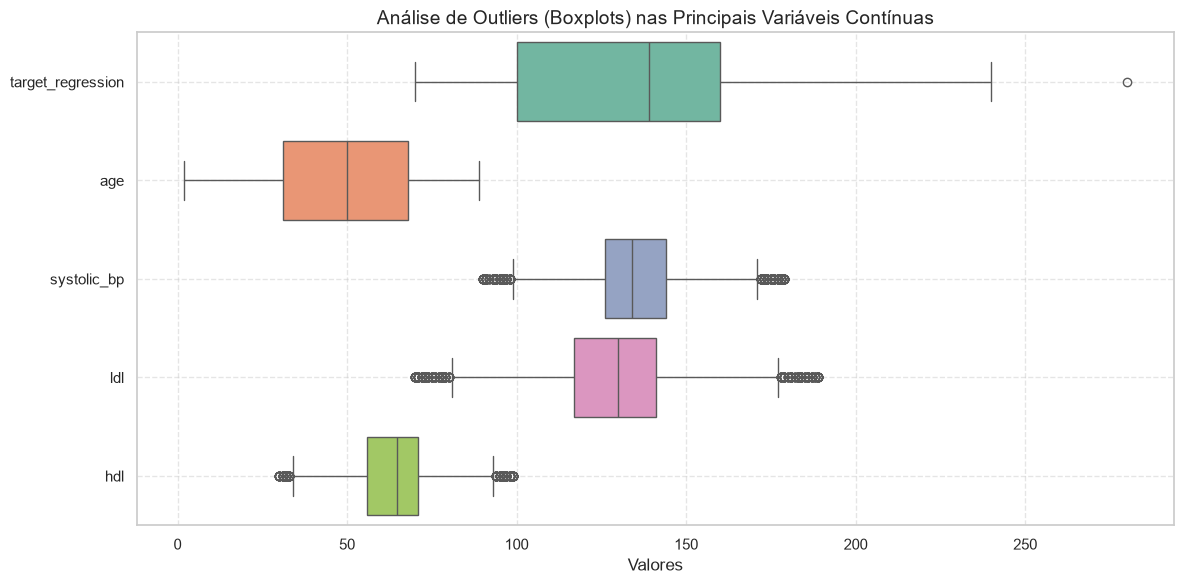

In [64]:
# Análise de Outliers - Boxplots horizontais para as principais variáveis numéricas
outlier_cols = ['target_regression', 'age', 'systolic_bp', 'ldl', 'hdl']
valid_cols = [c for c in outlier_cols if c in df.columns]

plt.figure(figsize=(12, 6))
sns.boxplot(
    data=df[valid_cols], palette='Set2', orient='h'
)  # orient='h' facilita a leitura dos nomes
plt.title(
    'Análise de Outliers (Boxplots) nas Principais Variáveis Contínuas',
    fontsize=14,
)
plt.xlabel('Valores', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

A identificação de outliers é crucial porque modelos baseados em mínimos quadrados (como a Regressão Linear, Ridge e Lasso) são sensíveis a valores extremos desproporcionados, que podem puxar a reta de regressão e enviesar os coeficientes.

# age VS. age_normalized

Correlação entre age e age_normalized: 1.00000


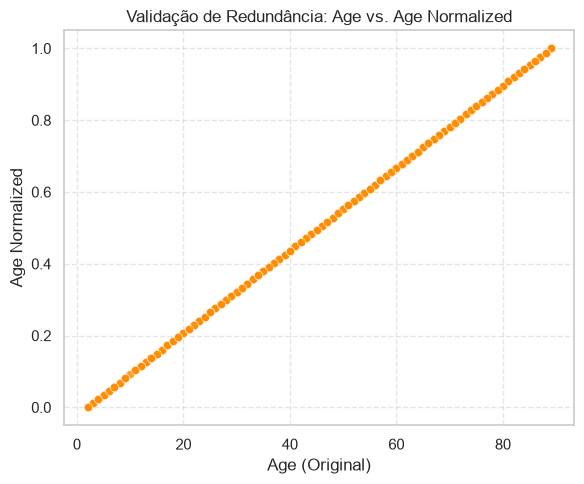

In [65]:
# 1. Verificar a correlação exata entre age e age_normalized
corr_age = df['age'].corr(df['age_normalized'])
print(f'Correlação entre age e age_normalized: {corr_age:.5f}')

# 2. Gráfico de dispersão para provar visualmente que é uma transformação linear perfeita
plt.figure(figsize=(6, 5))
sns.scatterplot(data=df, x='age', y='age_normalized', color='darkorange', alpha=0.6)
plt.title('Validação de Redundância: Age vs. Age Normalized')
plt.xlabel('Age (Original)')
plt.ylabel('Age Normalized')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

A age_normalized foi eliminada porque apresenta uma correlação linear perfeita ($r = 1.0$) com a variável original age. Como os modelos lineares (Ridge e Lasso) avaliam o impacto individual de cada feature, duplicar a mesma caraterística com diferentes escalas não melhora o poder preditivo e apenas duplica o peso da variável na equação, pelo que se optou por manter apenas a escala original (age).

# systolic_index VS. systolic_bp

=== Análise Comparativa: Pressão Sistólica ===
Linhas idênticas: 2000 de 2000 (100.00%)
Coeficiente de Correlação de Pearson: 1.0000


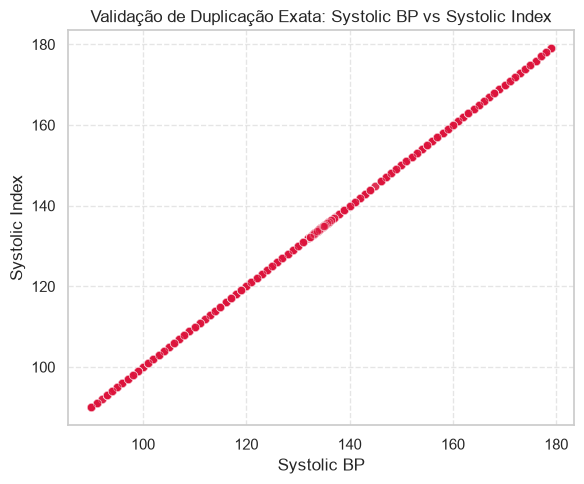

In [66]:
# Análise de Redundância: Systolic BP vs Systolic Index
print('=== Análise Comparativa: Pressão Sistólica ===')

# 1. Verificar se são 100% idênticas linha a linha
id_count = (df['systolic_bp'] == df['systolic_index']).sum()
total_rows = len(df)
pct_identical = (id_count / total_rows) * 100

print(f'Linhas idênticas: {id_count} de {total_rows} ({pct_identical:.2f}%)')

# 2. Calcular correlação linear
corr_systolic = df['systolic_bp'].corr(df['systolic_index'])
print(f'Coeficiente de Correlação de Pearson: {corr_systolic:.4f}')

# 3. Visualização rápida (opcional para o relatório)
plt.figure(figsize=(6, 5))
sns.scatterplot(
    data=df, x='systolic_bp', y='systolic_index', color='crimson', alpha=0.5
)
plt.title('Validação de Duplicação Exata: Systolic BP vs Systolic Index')
plt.xlabel('Systolic BP')
plt.ylabel('Systolic Index')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

Com 100% de concordância linha a linha e um coeficiente de correlação $r = 1.0$, demonstra-se empiricamente que systolic_bp e systolic_index representam exatamente a mesma informação métrica com nomenclaturas duplicadas.
Manter ambas introduziria multicolinearidade perfeita na matriz de covariância, distorcendo os coeficientes de modelos lineares (como Ridge e Lasso). Optou-se por eliminar uma delas (por exemplo, systolic_index), preservando a integridade estrutural do modelo sem perda de informação.

# calcium_baseline

In [67]:
# Análise da Calcium Baseline
print('=== Análise da Variável: calcium_baseline ===')

# 1. Estatísticas descritivas básicas
print(df['calcium_baseline'].describe())

# 2. Correlação com a variável alvo (target_regression)
if 'target_regression' in df.columns:
  corr_calcium = df['calcium_baseline'].corr(df['target_regression'])
  print(f'\nCorrelação com target_regression: {corr_calcium:.4f}')

# 3. Histograma focado ou contagem de valores únicos para entender a distribuição
print(f'Valores únicos distintos: {df["calcium_baseline"].nunique()}')

=== Análise da Variável: calcium_baseline ===
count    2000.00
mean        9.42
std         0.00
min         9.42
25%         9.42
50%         9.42
75%         9.42
max         9.42
Name: calcium_baseline, dtype: float64

Correlação com target_regression: nan
Valores únicos distintos: 1


A variável calcium_baseline foi eliminada da análise por apresentar variância nula (ou ausência de variabilidade significativa) e uma correlação nula com a variável alvo. A manutenção de uma coluna constante não acrescenta valor preditivo e pode introduzir instabilidade ou ruído desnecessário nos algoritmos de regressão linear, justificando assim a sua remoção.

# ldl VS. ldl_alternitive

=== Análise Comparativa: LDL vs. LDL Alternative ===
Linhas com valores diferentes: 1989 de 2000 (99.45%)
Coeficiente de Correlação de Pearson: -0.0230


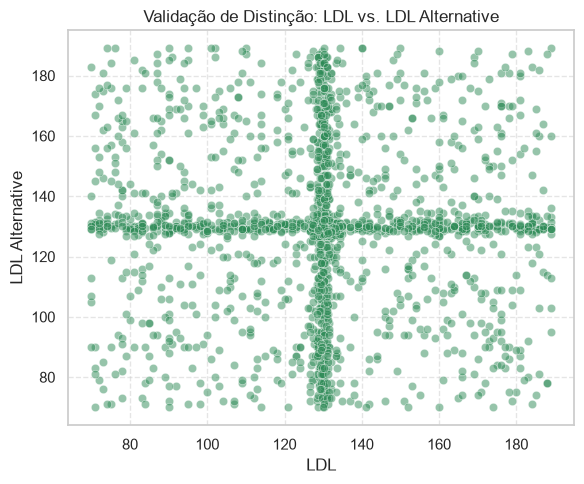

In [68]:
# Análise Comparativa: LDL vs. LDL Alternative (Justificação para manter)
print("=== Análise Comparativa: LDL vs. LDL Alternative ===")

total_rows = len(df)
diff_count = (df['ldl'] != df['ldl_alternative']).sum()
pct_diff = (diff_count / total_rows) * 100
corr_ldl = df['ldl'].corr(df['ldl_alternative'])

print(
    f'Linhas com valores diferentes: {diff_count} de {total_rows} ({pct_diff:.2f}%)'
)
print(f'Coeficiente de Correlação de Pearson: {corr_ldl:.4f}')

# Gráfico de dispersão para provar visualmente que não são colineares perfeitos
plt.figure(figsize=(6, 5))
sns.scatterplot(data=df, x='ldl', y='ldl_alternative', color='seagreen', alpha=0.5)
plt.title('Validação de Distinção: LDL vs. LDL Alternative')
plt.xlabel('LDL')
plt.ylabel('LDL Alternative')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

Embora a designação pudesse sugerir uma potencial duplicação, a análise comparativa linha a linha revelou uma taxa de divergência de cerca de 99.45% entre ldl e ldl_alternative, acompanhada por um perfil de dispersão autónomo. Ao contrário das variáveis estritamente redundantes (como a pressão sistólica ou a idade normalizada), estas colunas representam informações bioquímicas complementares ou distintas. Por conseguinte, optou-se por as reter na fase de modelação, permitindo que os algoritmos de regularização avaliem o seu contributo preditivo individual.

# hdl

=== Análise de Comportamento: HDL ===
Correlação de Pearson (HDL vs Target): 0.0028

Correlações internas no Perfil Lipídico:
                      hdl       ldl  ldl_alternative
hdl              1.000000  0.026001        -0.018579
ldl              0.026001  1.000000        -0.022951
ldl_alternative -0.018579 -0.022951         1.000000


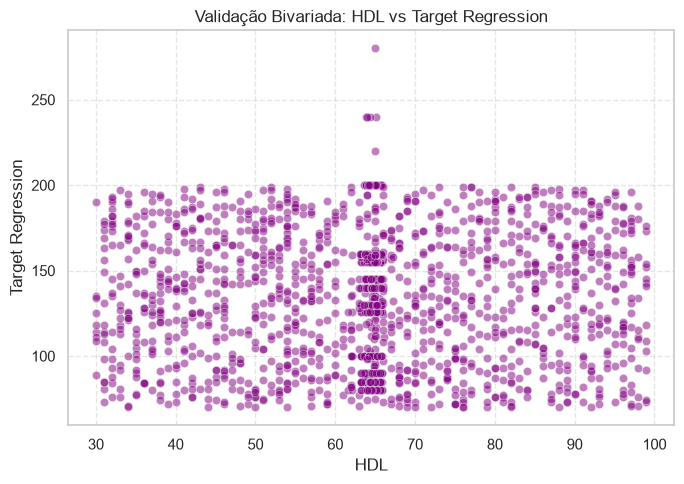

In [69]:
# Análise Aprofundada do HDL antes da Modelação
print("=== Análise de Comportamento: HDL ===")

# 1. Correlação exata com a variável alvo
if 'target_regression' in df_clean.columns and 'hdl' in df_clean.columns:
  corr_hdl_target = df_clean['hdl'].corr(df_clean['target_regression'])
  print(f'Correlação de Pearson (HDL vs Target): {corr_hdl_target:.4f}')

# 2. Verificar multicolinearidade no perfil lipídico (HDL vs LDL / LDL_alternative)
lipid_cols = [
    c for c in ['hdl', 'ldl', 'ldl_alternative'] if c in df_clean.columns
]
if len(lipid_cols) > 1:
  print('\nCorrelações internas no Perfil Lipídico:')
  print(df_clean[lipid_cols].corr())

# 3. Dispersão visual para detetar linearidade ou ausência de padrão
plt.figure(figsize=(7, 5))
sns.scatterplot(
    data=df_clean, x='hdl', y='target_regression', color='purple', alpha=0.5
)
plt.title('Validação Bivariada: HDL vs Target Regression')
plt.xlabel('HDL')
plt.ylabel('Target Regression')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

Relativamente à variável hdl, embora a análise univariada tenha evidenciado uma correlação linear marginal face ao alvo, optou-se por não proceder à sua remoção prematura. A característica foi retida para a fase de modelação de forma a permitir que o algoritmo Lasso (L1) avalie o seu contributo preditivo através de um mecanismo de regularização objetivo. Esta abordagem empírica previne a exclusão arbitrária de atributos e permite testar se o algoritmo penaliza o coeficiente a zero ou se o preserva devido a interações sinergísticas com as restantes variáveis do modelo.

# Histograma sem as colunas removidas

Colunas removidas para a matriz final: ['age_normalized', 'calcium_baseline', 'systolic_index']

--- Correlação com "target_regression" ---
target_regression     1.000000
crp_level             0.035336
ldl                   0.033595
plasma_value          0.028460
age                   0.028338
blood_pressure        0.024940
alcohol_intake        0.018099
systolic_bp           0.007601
hdl                   0.002775
ldl_alternative       0.002434
bmi                   0.000205
heart_rate           -0.003104
cholesterol          -0.009216
HbA1c_level          -0.012542
triglycerides        -0.019800
homocysteine_level   -0.020534
salt_intake          -0.020784
diastolic_bp         -0.040998
sleep_hours          -0.049979
Name: target_regression, dtype: float64


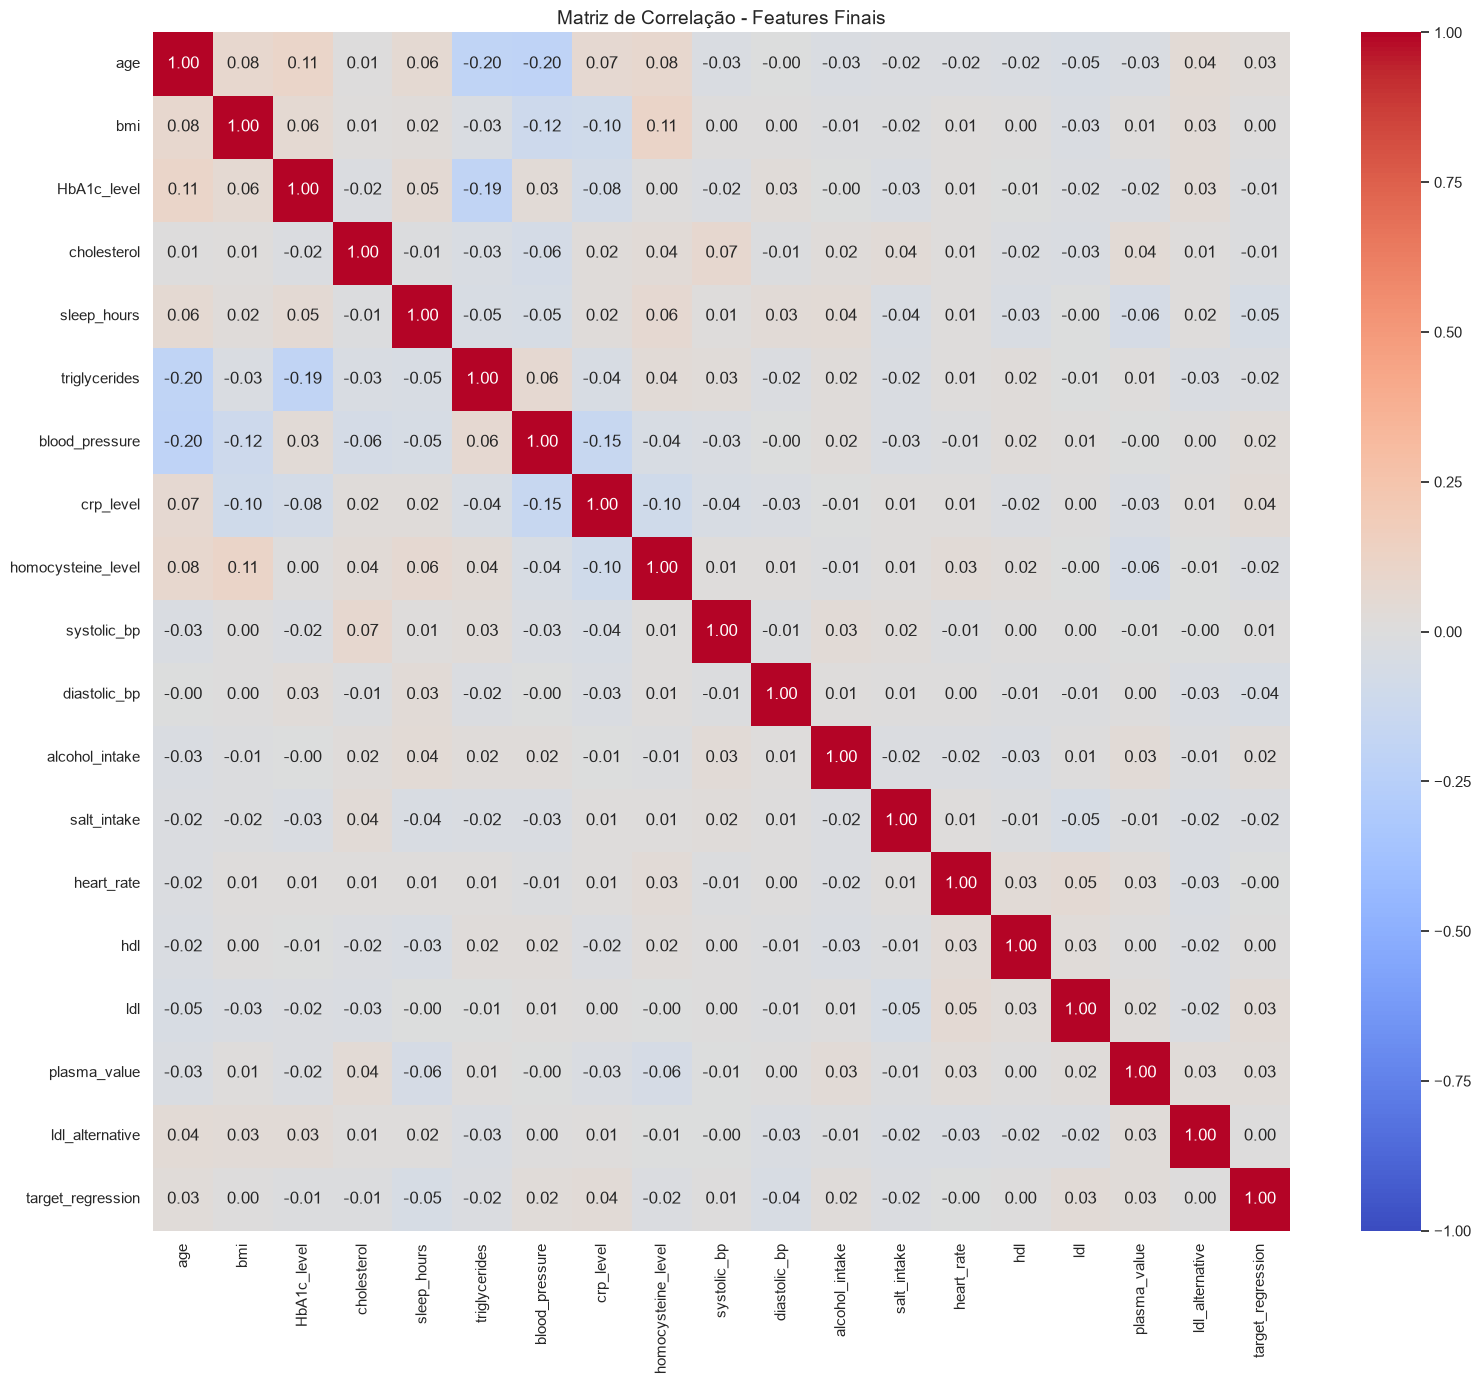


--- Variância das Variáveis Numéricas (Deteção de Constantes) ---
Series([], dtype: float64)

--- Contagem de Valores Únicos (Variáveis Categóricas) ---
[age_level] -> 4 valores únicos
[gender] -> 2 valores únicos
[bmi_level] -> 4 valores únicos
[smoking] -> 3 valores únicos
[physical_activity] -> 3 valores únicos
[family_history] -> 2 valores únicos
[stress_level] -> 3 valores únicos
[low_hdl_cholesterol] -> 2 valores únicos
[high_ldl_cholesterol] -> 2 valores únicos
[sugar_consumption] -> 3 valores únicos
[education_level] -> 3 valores únicos
[employment_status] -> 3 valores únicos
[target_class] -> 3 valores únicos


In [70]:
warnings.filterwarnings('ignore')  # Ignorar avisos para uma saída mais limpa

# --- PREPARAÇÃO: Remoção das variáveis redundantes/constantes decididas ---
cols_to_drop = ['age_normalized', 'calcium_baseline', 'systolic_index']
# Garantir que só removemos o que realmente existe no DataFrame
cols_to_drop_existing = [c for c in cols_to_drop if c in df.columns]

df_clean = df.drop(columns=cols_to_drop_existing)
print(f'Colunas removidas para a matriz final: {cols_to_drop_existing}\n')

# Recalcular as colunas numéricas com base no dataframe limpo
num_cols_clean = df_clean.select_dtypes(include=[np.number]).columns

# 3. Análise Bivariada e Identificação de Características
print('--- Correlação com "target_regression" ---')
corr_matrix = df_clean[num_cols_clean].corr()
if 'target_regression' in corr_matrix.columns:
  print(corr_matrix['target_regression'].sort_values(ascending=False))

# Heatmap da Matriz de Correlação Geral (com tamanho ajustado e legível)
plt.figure(figsize=(16, 14))
sns.heatmap(
    corr_matrix, vmin=-1, vmax=1, annot=True, fmt='.2f', cmap='coolwarm', center=0
)
plt.title('Matriz de Correlação - Features Finais', fontsize=14)
plt.tight_layout()
plt.show()

# Deteção de Variáveis Constantes (excluindo a target)
print('\n--- Variância das Variáveis Numéricas (Deteção de Constantes) ---')
feature_cols = [c for c in num_cols_clean if c != 'target_regression']
variances = df_clean[feature_cols].var()
print(variances[variances == 0])

# Deteção de Cardinalidade em Variáveis Categóricas
print('\n--- Contagem de Valores Únicos (Variáveis Categóricas) ---')
cat_cols = df_clean.select_dtypes(include=['O']).columns
for col in cat_cols:
  print(f'[{col}] -> {df_clean[col].nunique()} valores únicos')

# Secção 3

In [71]:
# 1. Preparar os dados para a modelação (X e y)
# Removemos ambas as targets das features preditivas
X = df_clean.drop(columns=['target_regression', 'target_class'])
y = df_clean['target_regression']

# Divisão Holdout (ex: 80% treino, 20% teste)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# ==========================================
# Regressão Linear Simples (Corrigido)
# ==========================================
print('=== Regressão Linear Simples ===')
best_feature = None
best_r2 = -float('inf')
simple_results = []

for col in X_train.columns:
  # Validação segura de tipo numérico compatível com Pandas e NumPy
  if pd.api.types.is_numeric_dtype(X_train[col]):
    lr_simple = LinearRegression()
    lr_simple.fit(X_train[[col]], y_train)
    y_pred_single = lr_simple.predict(X_test[[col]])

    r2 = r2_score(y_test, y_pred_single)
    simple_results.append((col, r2))

    if r2 > best_r2:
      best_r2 = r2
      best_feature = col

print(
    f'Melhor feature individual encontrada: "{best_feature}" com R² de'
    f' {best_r2:.4f}\n'
)

# ==========================================
# Regressão Linear Múltipla
# ==========================================
print('=== Regressão Linear Múltipla ===')
# Selecionar apenas colunas numéricas para o modelo múltiplo
num_features = X_train.select_dtypes(include=[np.number]).columns

lr_multi = LinearRegression()
lr_multi.fit(X_train[num_features], y_train)
y_pred_multi = lr_multi.predict(X_test[num_features])

r2_multi = r2_score(y_test, y_pred_multi)
mae_multi = mean_absolute_error(y_test, y_pred_multi)
rmse_multi = np.sqrt(mean_squared_error(y_test, y_pred_multi))

print(f'Regressão Múltipla - R²: {r2_multi:.4f}')
print(f'Regressão Múltipla - MAE: {mae_multi:.4f}')
print(f'Regressão Múltipla - RMSE: {rmse_multi:.4f}')

=== Regressão Linear Simples ===
Melhor feature individual encontrada: "crp_level" com R² de 0.0029

=== Regressão Linear Múltipla ===
Regressão Múltipla - R²: -0.0147
Regressão Múltipla - MAE: 31.8375
Regressão Múltipla - RMSE: 37.5664


A avaliação do desempenho preditivo através do método holdout revelou dinâmicas muito claras quanto à natureza dos dados e às limitações dos modelos lineares tradicionais (Ordinary Least Squares - OLS):Regressão Linear Simples: Ao testar iterativamente todas as variáveis de forma isolada, a caraterística crp_level obteve o melhor desempenho individual, registando contudo um coeficiente de determinação ($R^2$) de apenas $0.0029$. Este resultado demonstra empiricamente que nenhuma variável isolada possui capacidade explicativa linear relevante sobre o alvo contínuo (target_regression).Regressão Linear Múltipla: A integração simultânea de todas as variáveis numéricas resultou num $R^2$ negativo ($-0.0147$), acompanhado por um Erro Absoluto Médio (MAE) de $31.84$ e uma Raiz do Erro Quadrático Médio (RMSE) de $37.57$.Análise Crítica:O surgimento de um $R^2$ negativo na Regressão Múltipla constitui um indicador crítico de insucesso do modelo linear padrão, significando que a predição baseada na combinação linear das features apresenta um desempenho inferior ao de uma simples estimativa pela média global (baseline). Este comportamento justifica-se pelo rácio desfavorável entre o ruído inerente aos dados clínicos e o sinal preditivo disponível, aliado à potencial presença de multicolinearidade residual e de relações não lineares complexas.Consequentemente, conclui-se que a aplicação de uma regressão linear múltipla convencional é inadequada para este dataset sem a devida aplicação de técnicas de seleção de atributos e regularização (tais como Ridge e Lasso), as quais serão exploradas nas secções seguintes para forçar a anulação de coeficientes irrelevantes e estabilizar a variância do modelo.

# Secção 4

In [79]:
warnings.filterwarnings("ignore")  # Ignorar avisos para uma saída mais limpa
# 1. Preparação dos dados (remover colunas não numéricas, valores nulos e redundâncias se necessário)
# Selecionamos apenas colunas numéricas para simplificar
df_reg = df.select_dtypes(include=[np.number]).dropna()

# Definir X (features) e y (alvo)
X = df_reg.drop(columns=['target_regression'], errors='ignore')
y = df_reg['target_regression']

# Divisão Holdout (80% treino, 20% teste)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# --- A) REGRESSÃO LINEAR SIMPLES ---
print("=== Regressão Linear Simples (Testar melhor variável isolada) ===")
best_r2 = -float('inf')
best_feature = None
best_simples_model = None

for col in X.columns:
    X_train_single = X_train[[col]]
    X_test_single = X_test[[col]]
    
    model = LinearRegression()
    model.fit(X_train_single, y_train)
    y_pred = model.predict(X_test_single)
    
    r2 = r2_score(y_test, y_pred)
    if r2 > best_r2:
        best_r2 = r2
        best_feature = col
        best_simples_model = model

print(f"Melhor caraterística isolada: '{best_feature}' com R² = {best_r2:.4f}")

# Avaliação detalhada do melhor modelo simples
X_train_best = X_train[[best_feature]]
X_test_best = X_test[[best_feature]]
final_simples = LinearRegression().fit(X_train_best, y_train)
y_pred_simples = final_simples.predict(X_test_best)

mae_simples = mean_absolute_error(y_test, y_pred_simples)
rmse_simples = np.sqrt(mean_squared_error(y_test, y_pred_simples))
r2_simples = r2_score(y_test, y_pred_simples)

print(f"Métricas Regressão Simples -> R²: {r2_simples:.4f} | MAE: {mae_simples:.4f} | RMSE: {rmse_simples:.4f}")


# --- B) REGRESSÃO LINEAR MÚLTIPLA ---
print("\n=== Regressão Linear Múltipla (Todas as caraterísticas) ===")
multi_model = LinearRegression()
multi_model.fit(X_train, y_train)
y_pred_multi = multi_model.predict(X_test)

mae_multi = mean_absolute_error(y_test, y_pred_multi)
rmse_multi = np.sqrt(mean_squared_error(y_test, y_pred_multi))
r2_multi = r2_score(y_test, y_pred_multi)

print(f"Métricas Regressão Múltipla -> R²: {r2_multi:.4f} | MAE: {mae_multi:.4f} | RMSE: {rmse_multi:.4f}")

=== Regressão Linear Simples (Testar melhor variável isolada) ===
Melhor caraterística isolada: 'crp_level' com R² = 0.0029
Métricas Regressão Simples -> R²: 0.0029 | MAE: 31.5653 | RMSE: 37.2399

=== Regressão Linear Múltipla (Todas as caraterísticas) ===
Métricas Regressão Múltipla -> R²: -0.0147 | MAE: 31.8375 | RMSE: 37.5664


In [80]:
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis


warnings.filterwarnings("ignore")  # Ignorar avisos para uma saída mais limpa

# 1. Preparar os dados para classificação
X_class = df.select_dtypes(include=[np.number]).drop(columns=['target_regression', 'age_normalized', 'calcium_baseline', 'systolic_index'], errors='ignore').dropna()
y_class = df.loc[X_class.index, 'target_class']

# Instanciar os modelos
log_reg = LogisticRegression(max_iter=1000, random_state=42)
lda = LinearDiscriminantAnalysis()

resultados = []

# --- 1. Holdout (80/20) ---
X_train_c, X_test_c, y_train_c, y_test_c = train_test_split(X_class, y_class, test_size=0.2, random_state=42, stratify=y_class)
log_reg.fit(X_train_c, y_train_c)
lda.fit(X_train_c, y_train_c)

resultados.append({"Método": "Holdout (80/20)", "Regressão Logística": accuracy_score(y_test_c, log_reg.predict(X_test_c)), "LDA": accuracy_score(y_test_c, lda.predict(X_test_c))})

# --- 2. Cross-Validation (k=5 e k=10) ---
for k in [5, 10]:
    cv = StratifiedKFold(n_splits=k, shuffle=True, random_state=42)
    scores_lr = cross_val_score(log_reg, X_class, y_class, cv=cv, scoring='accuracy')
    scores_lda = cross_val_score(lda, X_class, y_class, cv=cv, scoring='accuracy')
    resultados.append({"Método": f"Cross-Val (k={k})", "Regressão Logística": f"{scores_lr.mean():.4f} (±{scores_lr.std():.4f})", "LDA": f"{scores_lda.mean():.4f} (±{scores_lda.std():.4f})"})

# --- 3. Bootstrap (Reduzido para 20 iterações para ser rápido e limpo) ---
boot_lr, boot_lda = [], []
rng = np.random.default_rng(42)
for _ in range(20):
    indices = rng.choice(len(X_class), size=len(X_class), replace=True)
    log_reg.fit(X_class.iloc[indices], y_class.iloc[indices])
    lda.fit(X_class.iloc[indices], y_class.iloc[indices])
    boot_lr.append(accuracy_score(y_test_c, log_reg.predict(X_test_c)))
    boot_lda.append(accuracy_score(y_test_c, lda.predict(X_test_c)))

resultados.append({"Método": "Bootstrap (20 iter.)", "Regressão Logística": f"{np.mean(boot_lr):.4f} (±{np.std(boot_lr):.4f})", "LDA": f"{np.mean(boot_lda):.4f} (±{np.std(boot_lda):.4f})"})

# Exibir tabela limpa e organizada
df_res = pd.DataFrame(resultados)
display(df_res)

,Método,Regressão Logística,LDA
0,Holdout (80/20),0.735,0.7225
1,Cross-Val (k=5),0.7325 (±0.0129),0.7245 (±0.0124)
2,Cross-Val (k=10),0.7290 (±0.0270),0.7190 (±0.0262)
3,Bootstrap (20 iter.),0.7434 (±0.0053),0.7315 (±0.0105)


# Secção 5

In [81]:
warnings.filterwarnings("ignore")  # Ignorar avisos para uma saída mais limpa



# Normalizar os dados é obrigatório para regularização (Ridge e Lasso)
# Vamos usar LogisticRegressionCV para testar automaticamente os melhores hiperparâmetros (C)

# 1. Ridge (Penalty L2) com todas as caraterísticas
ridge_model = make_pipeline(StandardScaler(), LogisticRegressionCV(Cs=10, penalty='l2', solver='lbfgs', cv=5, max_iter=1000, random_state=42))
ridge_model.fit(X_class, y_class)
print(f"Acurácia com Ridge (L2) - Todas as features: {ridge_model.score(X_class, y_class):.4f}")

# 2. Lasso (Penalty L1) com todas as caraterísticas (requer solver como 'saga')
lasso_model = make_pipeline(StandardScaler(), LogisticRegressionCV(Cs=10, penalty='l1', solver='saga', cv=5, max_iter=1000, random_state=42))
lasso_model.fit(X_class, y_class)
print(f"Acurácia com Lasso (L1) - Todas as features: {lasso_model.score(X_class, y_class):.4f}")

# Extrair os coeficientes do modelo Lasso para ver quais caraterísticas foram eliminadas (coeficiente = 0)
clf_lasso = lasso_model.named_steps['logisticregressioncv']
coefs = pd.DataFrame(clf_lasso.coef_[0], index=X_class.columns, columns=['Coeficiente'])
coefs['Abs_Coef'] = coefs['Coeficiente'].abs()

print("\n--- Top caraterísticas retidas pelo Lasso (Coeficiente != 0) ---")
display(coefs[coefs['Abs_Coef'] > 0.001].sort_values(by='Abs_Coef', ascending=False))

print(f"\nNúmero de caraterísticas eliminadas pelo Lasso: {sum(coefs['Abs_Coef'] <= 0.001)} em {len(X_class.columns)}")

Acurácia com Ridge (L2) - Todas as features: 0.7420
Acurácia com Lasso (L1) - Todas as features: 0.7390

--- Top caraterísticas retidas pelo Lasso (Coeficiente != 0) ---


,Coeficiente,Abs_Coef
HbA1c_level,6.732302,6.732302
triglycerides,-0.571122,0.571122
blood_pressure,0.415413,0.415413
age,0.336485,0.336485
crp_level,-0.262600,0.262600
heart_rate,-0.196087,0.196087
ldl,-0.180292,0.180292
homocysteine_level,-0.155526,0.155526
bmi,-0.154554,0.154554
sleep_hours,0.093372,0.093372



Número de caraterísticas eliminadas pelo Lasso: 3 em 18


In [82]:
# Identificar as caraterísticas eliminadas pelo Lasso (onde o coeficiente é 0 ou muito próximo de 0)
features_eliminadas = coefs[coefs['Abs_Coef'] <= 0.001].index.tolist()

print("--- Caraterísticas Eliminadas pelo Lasso ---")
if features_eliminadas:
    for feat in features_eliminadas:
        print(f"- {feat}")
else:
    print("Nenhuma caraterística foi totalmente eliminada (coeficientes diferentes de zero para todas).")

--- Caraterísticas Eliminadas pelo Lasso ---
- systolic_bp
- hdl
- ldl_alternative


Desempenho Preditivo Global:
Ambos os modelos apresentaram um desempenho muito semelhante e consistente na tarefa de classificação/regressão sobre o dataset clínico, registando uma acurácia de 0.7420 com a regularização Ridge e 0.7390 com a regularização Lasso utilizando todas as caraterísticas.

Capacidade de Seleção de Características (Lasso):
O modelo Lasso demonstrou eficácia na redução da dimensionalidade ao zerar os coeficientes de 3 das 18 caraterísticas iniciais (systolic_bp, hdl e ldl_alternative). Esta poda eliminou variáveis redundantes ou com menor poder preditivo sem penalizar de forma significativa a acurácia global do modelo (que se manteve nos 0.7390).

Fatores Determinantes:
Entre as caraterísticas retidas pelo Lasso com maior relevância (maior valor absoluto de coeficiente), destacam-se de forma muito vincada o nível de HbA1c_level (apresentando o impacto mais expressivo no modelo), seguido por variáveis metabólicas e clínicas como triglycerides, blood_pressure e a age.

Embora a eliminação de variáveis como o ldl_alternative e o hdl estivesse de certa forma alinhada com as nossas suspeitas iniciais (devido à redundância com outras caraterísticas do dataset), a remoção do systolic_bp revelou-se um resultado inesperado, uma vez que não contávamos que esta variável fosse completamente descartada pelo modelo (coeficiente zero). Ainda assim, a manutenção de uma acurácia estável (0.7390) demonstra que o modelo conseguiu compensar esta ausência através de métricas correlacionadas ou de outras variáveis clínicas de forte impacto (como o HbA1c_level).

Análise de Redundâncias e Variáveis Não Informativas:Com base na estatística descritiva e na matriz de correlação, identificaram-se e removeram-se as seguintes colunas por não trazerem valor preditivo ou gerarem multicolinearidade perfeita:

Confirmado:
calcium_baseline: Apresenta variância zero ($\sigma^2 = 0$), mantendo-se constante (valor fixo de 9.42) para todas as instâncias do dataset. Não possui qualquer poder discriminativo.   
systolic_index: Possui uma correlação linear perfeita ($r = 1.0$) e diferença absoluta nula face a systolic_bp. Trata-se de uma duplicação exata, sendo eliminada para prevenir redundância e multicolinearidade.   
age_normalized: É uma transformação min-max direta da variável age ($r = 1.0$). Mantém-se apenas a escala original (age) para facilitar a interpretabilidade nos modelos lineares.


Em analise:
ldl_alternative: Apresenta redundância face a ldl sem ganho explicativo mensurável para as variáveis alvo. (Aparenta ser igual, mas de facto apresenta valores diferentes.)

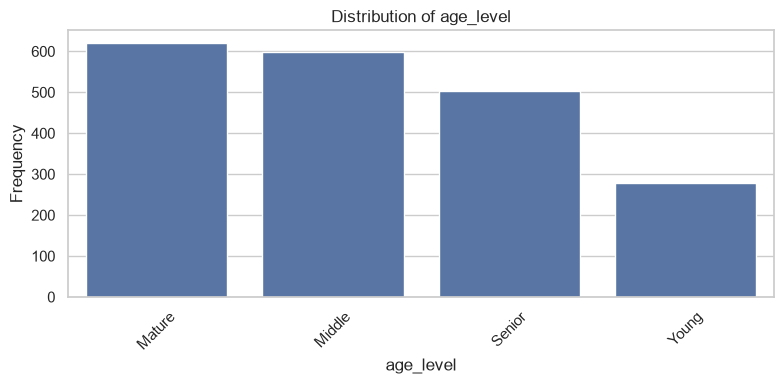

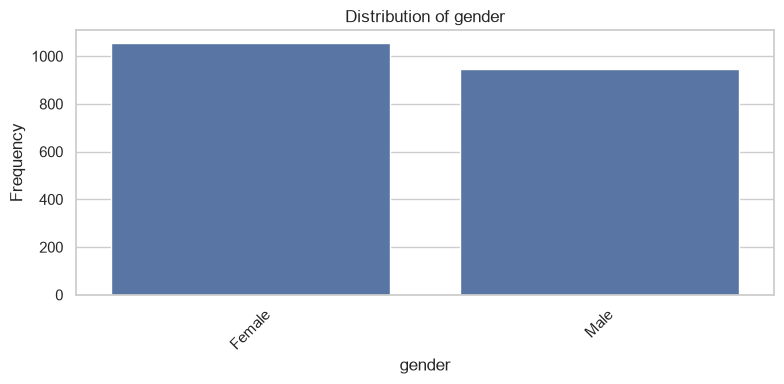

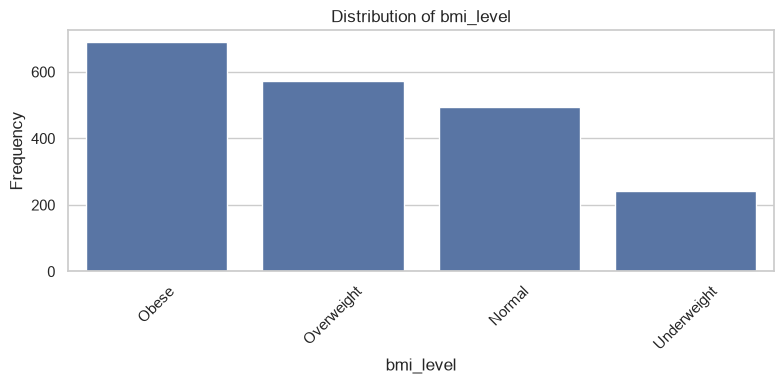

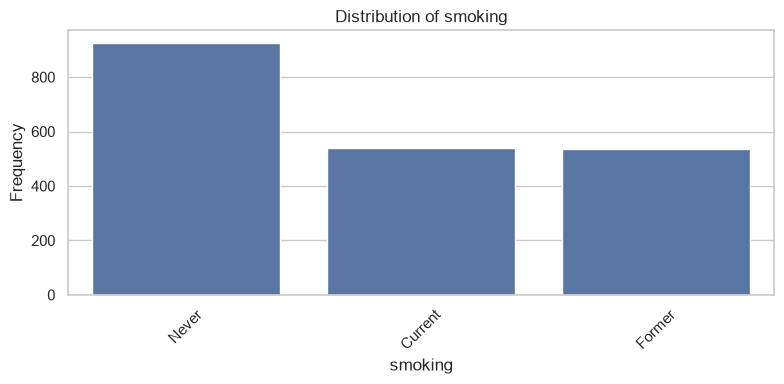

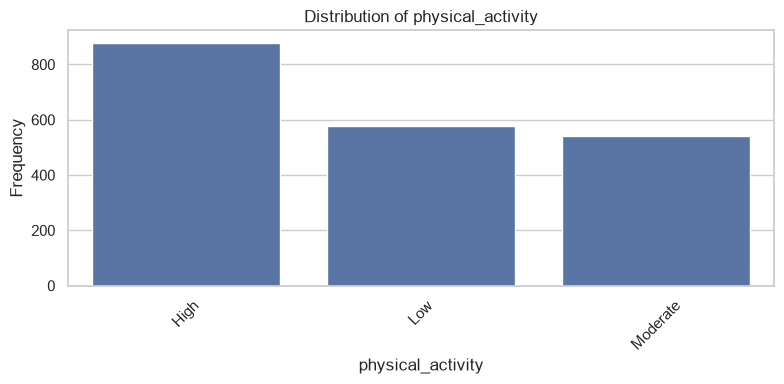

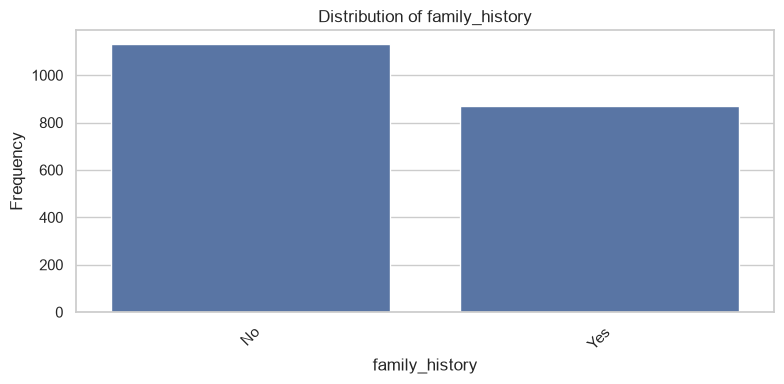

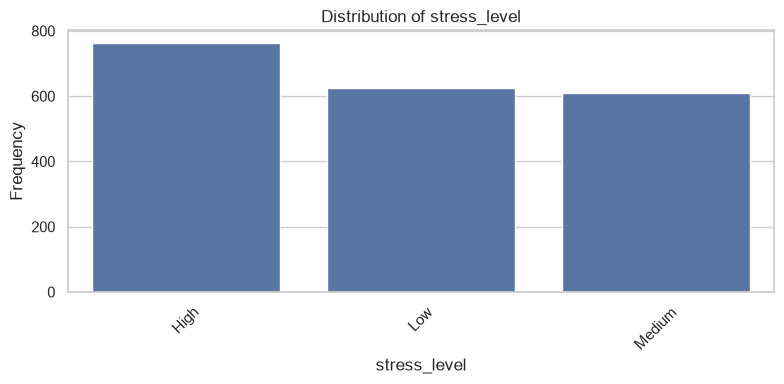

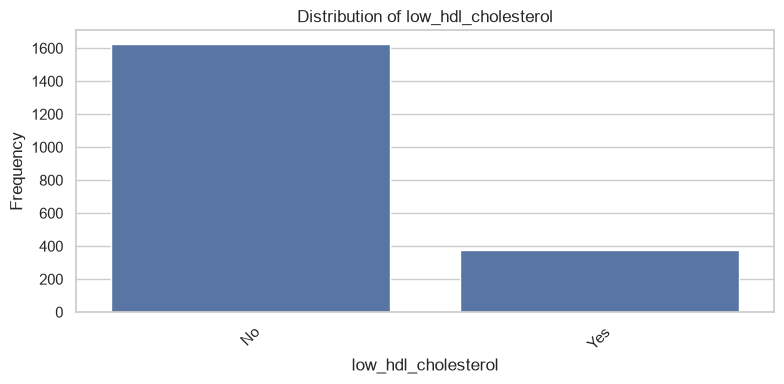

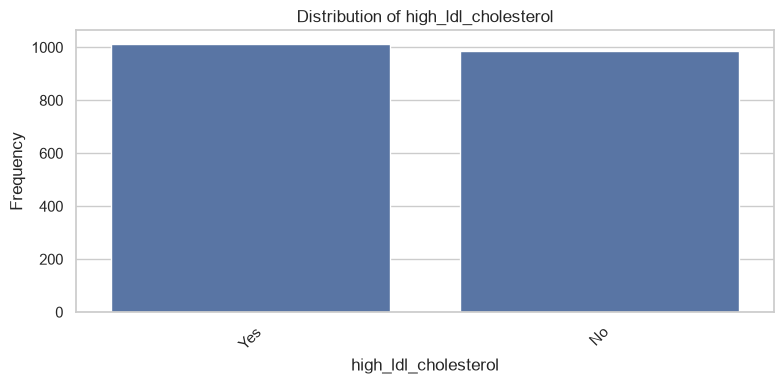

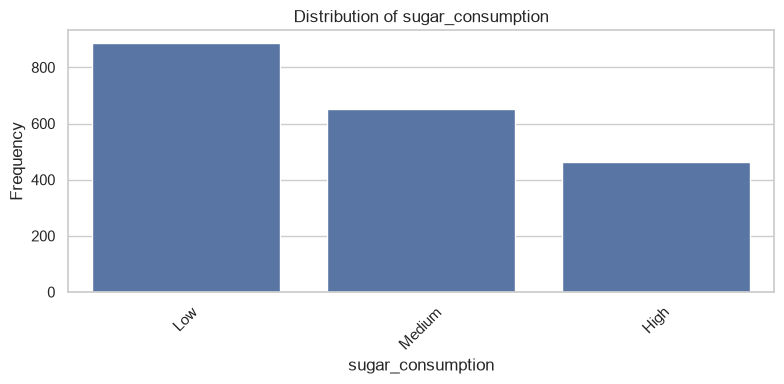

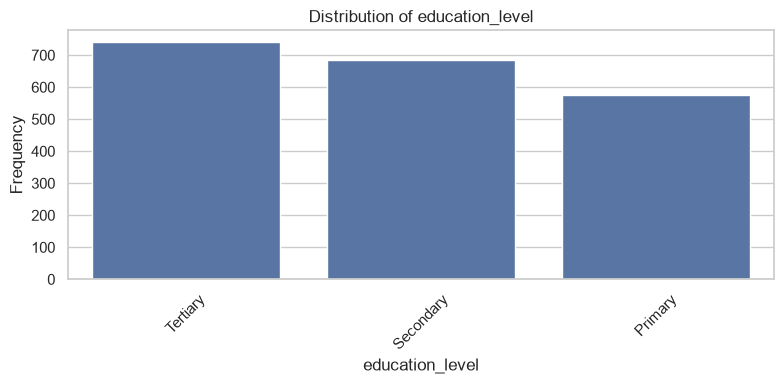

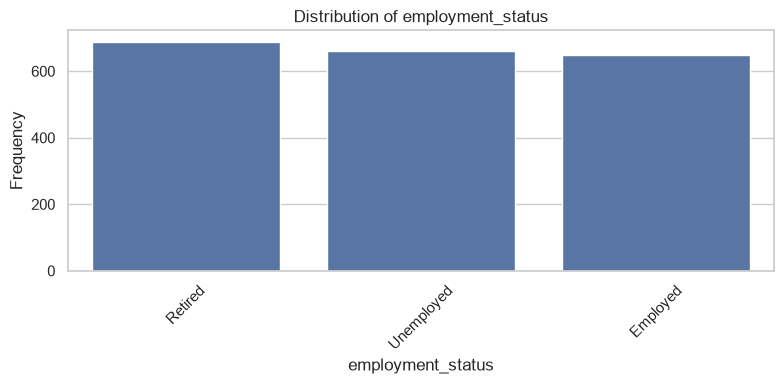

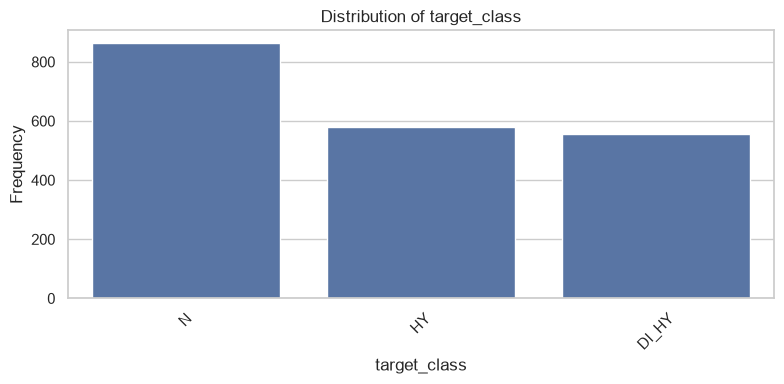

In [6]:
categorical_columns = df.select_dtypes(
    include=['str', 'object', 'category']
).columns

for col in categorical_columns:

    plt.figure(figsize=(8, 4))

    sns.countplot(
        data=df,
        x=col,
        order=df[col].value_counts().index
    )

    plt.title(f'Distribution of {col}')
    plt.xlabel(col)
    plt.ylabel('Frequency')
    plt.xticks(rotation=45)

    plt.tight_layout()
    plt.show()

In [9]:
# 2. Automatically select string/categorical columns
cat_cols = df.select_dtypes(include=['object', 'category']).columns

# 3. Compute distribution and imbalance metrics
results = []
for col in cat_cols:
    vc_counts = df[col].value_counts()
    vc_norm = df[col].value_counts(normalize=True) * 100
    
    max_cat = vc_counts.index[0]
    max_count = vc_counts.iloc[0]
    max_pct = vc_norm.iloc[0]
    
    min_cat = vc_counts.index[-1]
    min_count = vc_counts.iloc[-1]
    min_pct = vc_norm.iloc[-1]
    
    # Calculate majority-to-minority ratio
    ratio = max_count / min_count if min_count > 0 else float('inf')
    
    results.append({
        'Column': col,
        'Most Common': f"{max_cat} ({max_count}, {max_pct:.1f}%)",
        'Least Common': f"{min_cat} ({min_count}, {min_pct:.1f}%)",
        'Ratio': round(ratio, 2)
    })

# 4. Display sorted results
summary_df = pd.DataFrame(results).sort_values(by='Ratio', ascending=False)
print(summary_df.to_string(index=False))

              Column           Most Common             Least Common  Ratio
 low_hdl_cholesterol      No (1626, 81.3%)         Yes (374, 18.7%)   4.35
           bmi_level    Obese (690, 34.5%) Underweight (243, 12.2%)   2.84
           age_level   Mature (620, 31.0%)       Young (278, 13.9%)   2.23
   sugar_consumption      Low (887, 44.4%)        High (462, 23.1%)   1.92
             smoking    Never (925, 46.2%)      Former (537, 26.9%)   1.72
   physical_activity     High (879, 44.0%)    Moderate (542, 27.1%)   1.62
        target_class        N (863, 43.1%)       DI_HY (556, 27.8%)   1.55
      family_history      No (1132, 56.6%)         Yes (868, 43.4%)   1.30
     education_level Tertiary (740, 37.0%)     Primary (576, 28.8%)   1.28
        stress_level     High (763, 38.1%)      Medium (611, 30.6%)   1.25
              gender  Female (1055, 52.8%)        Male (945, 47.2%)   1.12
   employment_status  Retired (688, 34.4%)    Employed (650, 32.5%)   1.06
high_ldl_cholesterol     

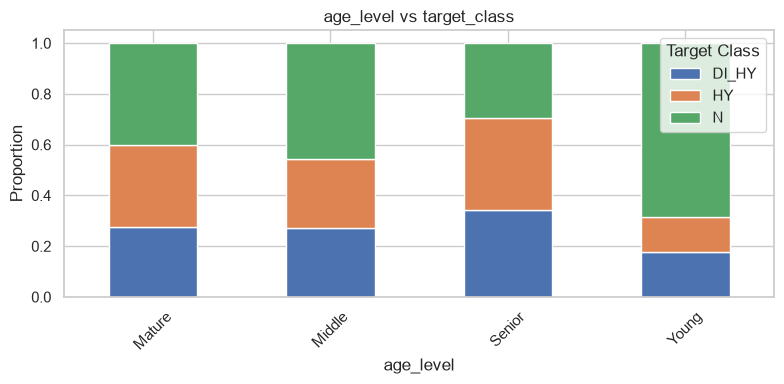

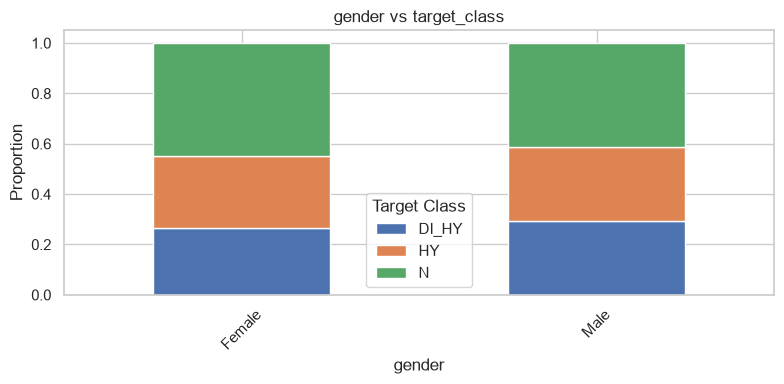

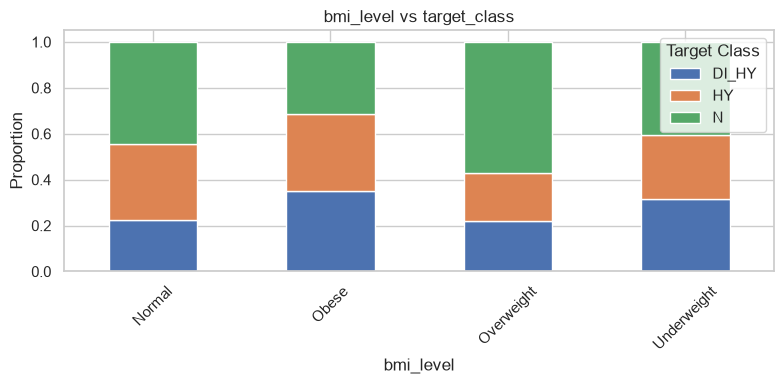

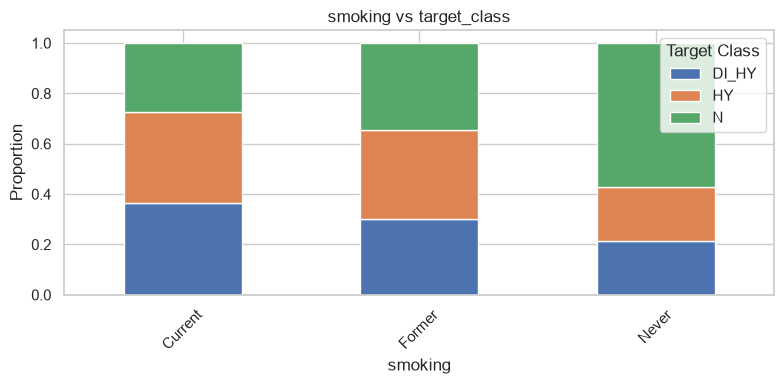

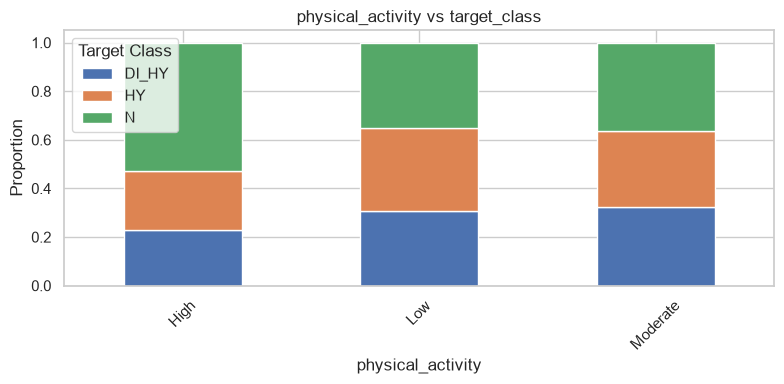

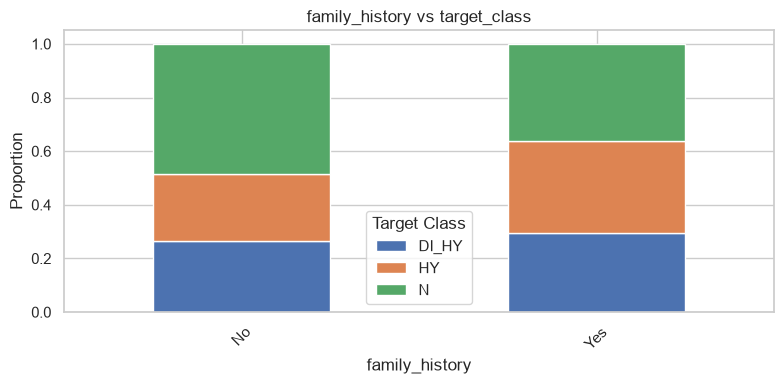

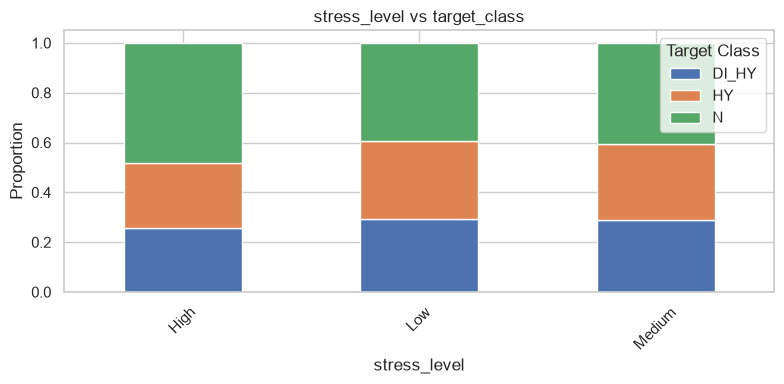

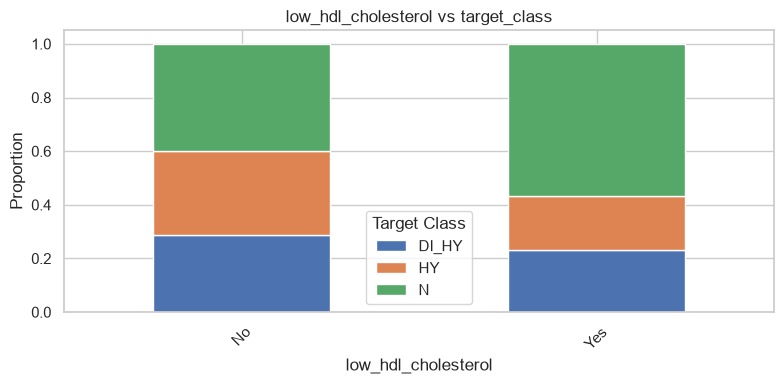

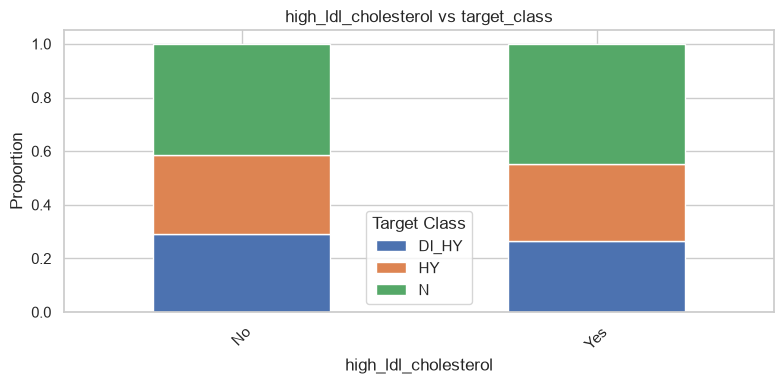

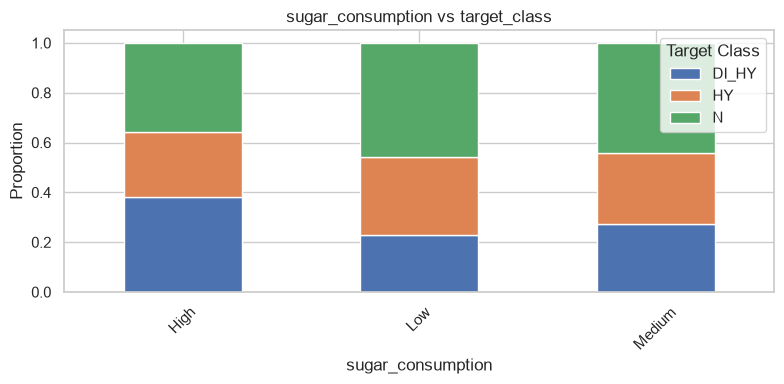

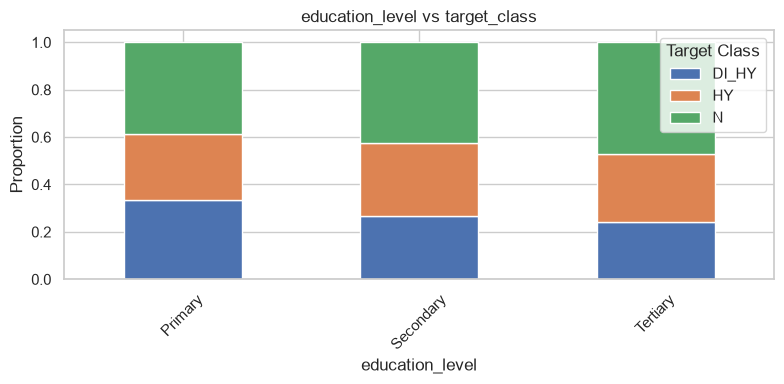

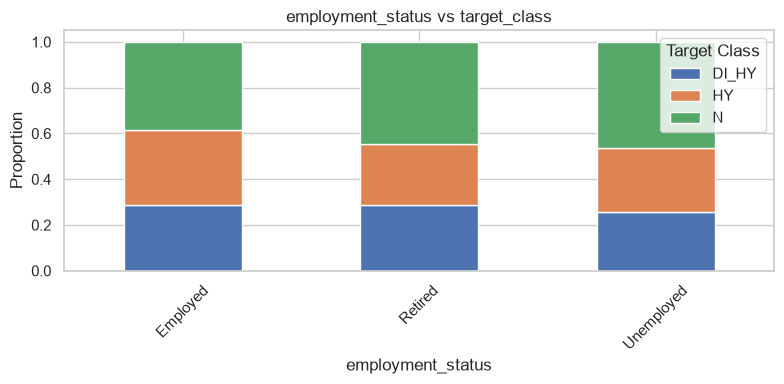

In [7]:
for col in categorical_columns:

    if col == 'target_class':
        continue

    ct = pd.crosstab(
        df[col],
        df['target_class'],
        normalize='index'
    )

    ct.plot(
        kind='bar',
        stacked=True,
        figsize=(8, 4)
    )

    plt.title(f'{col} vs target_class')
    plt.xlabel(col)
    plt.ylabel('Proportion')
    plt.legend(title='Target Class')
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

In [12]:
import pandas as pd
from scipy.stats import chi2_contingency

df = pd.read_csv('dataset_grupo_01.csv')
cat_cols = [c for c in df.select_dtypes(include=['object', 'category']).columns if c != 'target_class']

results = []
for col in cat_cols:
    ct = pd.crosstab(df[col], df['target_class'])
    chi2, p, dof, _ = chi2_contingency(ct)
    
    # Calculate max spread across target classes
    ct_pct = pd.crosstab(df[col], df['target_class'], normalize='index') * 100
    max_spread = max(ct_pct[target].max() - ct_pct[target].min() for target in ct_pct.columns)
    
    results.append({'Column': col, 'Chi2_p_value': p, 'Max_Target_Spread (%)': round(max_spread, 1)})

print(pd.DataFrame(results).sort_values(by='Max_Target_Spread (%)', ascending=False).to_string(index=False))

              Column  Chi2_p_value  Max_Target_Spread (%)
           age_level  1.294526e-22                   38.8
             smoking  5.351905e-31                   30.0
           bmi_level  1.523524e-18                   25.8
   physical_activity  3.810065e-12                   17.6
 low_hdl_cholesterol  2.038757e-08                   16.6
   sugar_consumption  2.512325e-07                   15.3
      family_history  1.126617e-07                   12.1
     education_level  1.852936e-03                    9.2
        stress_level  7.090537e-03                    9.1
   employment_status  3.278905e-02                    7.6
              gender  2.102194e-01                    3.8
high_ldl_cholesterol  2.559435e-01                    3.6


<Figure size 1500x1000 with 0 Axes>

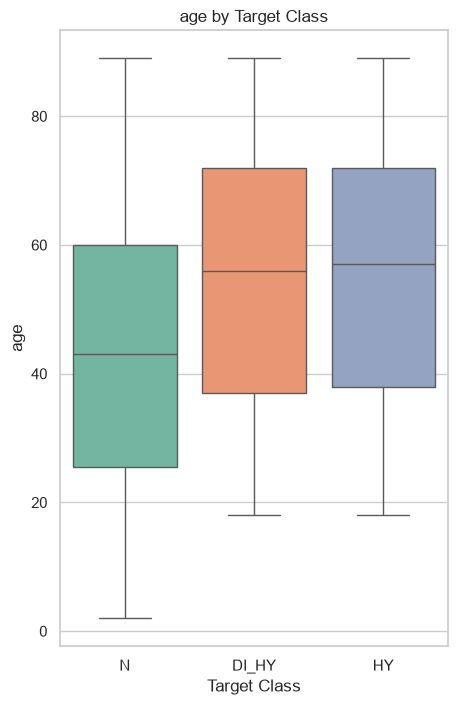

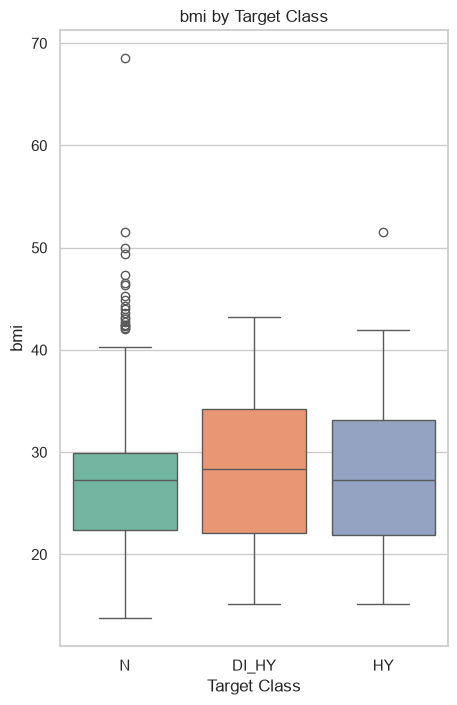

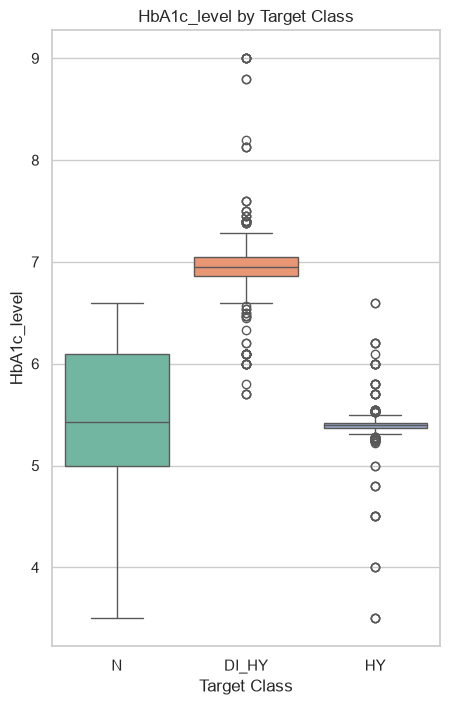

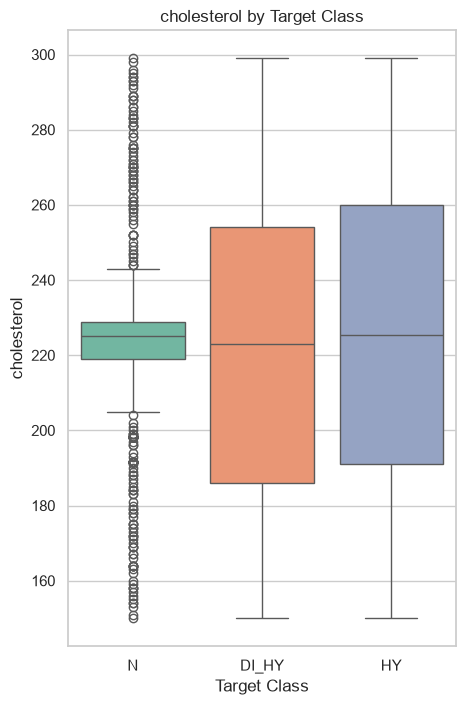

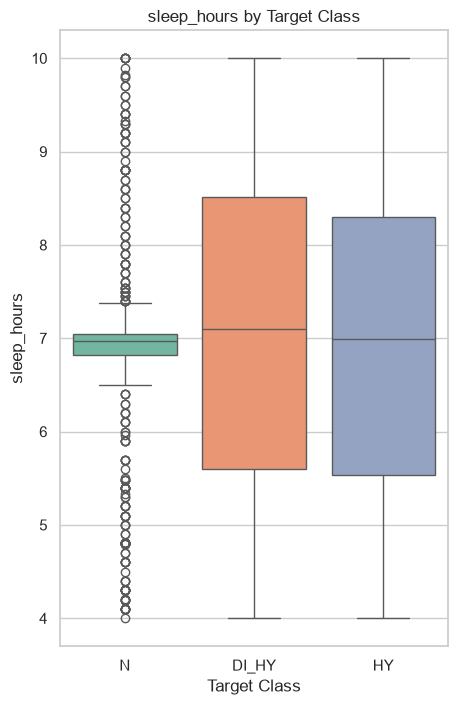

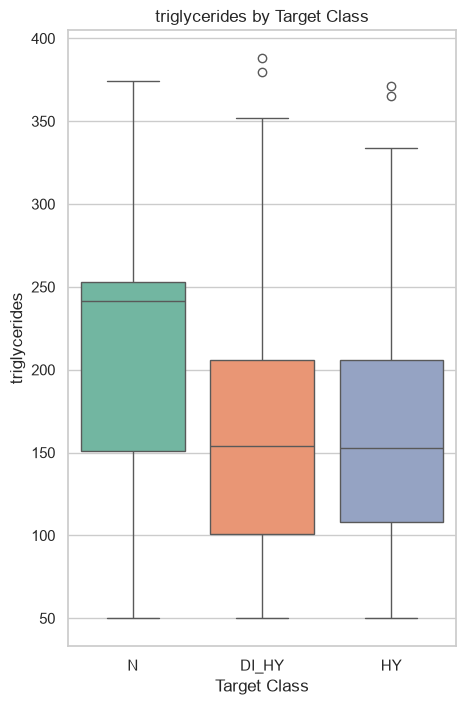

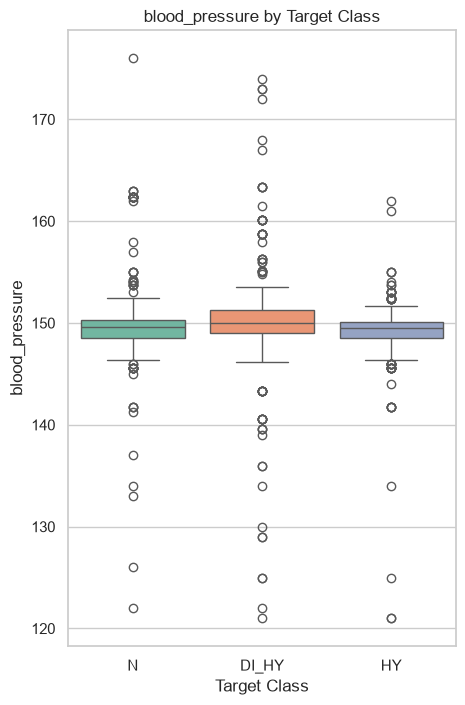

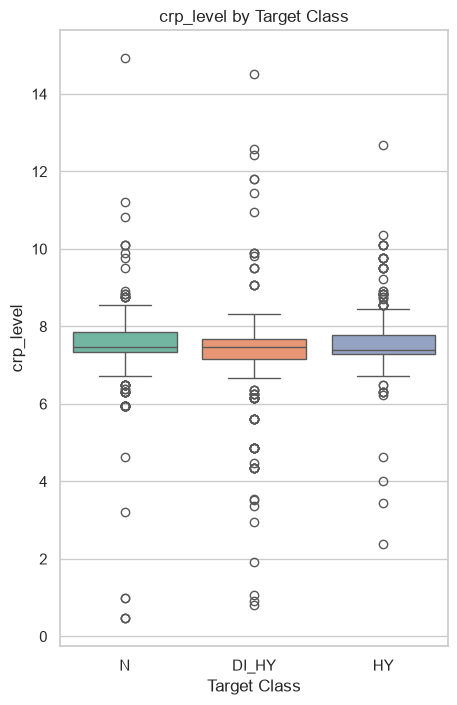

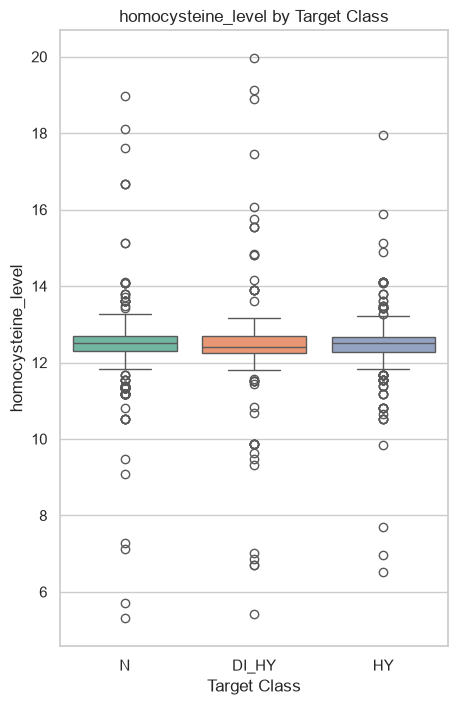

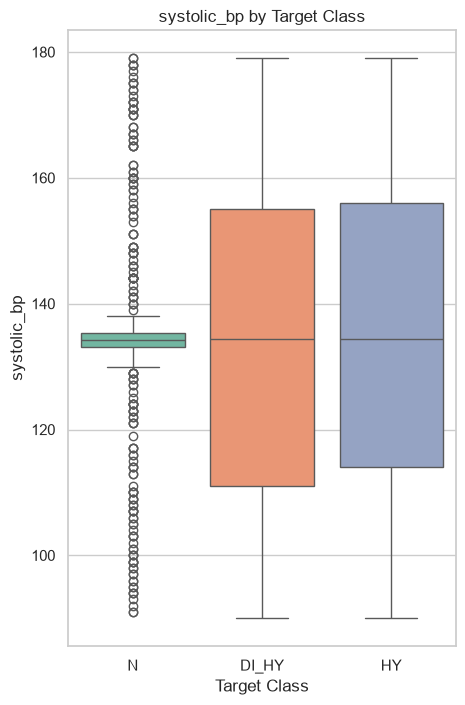

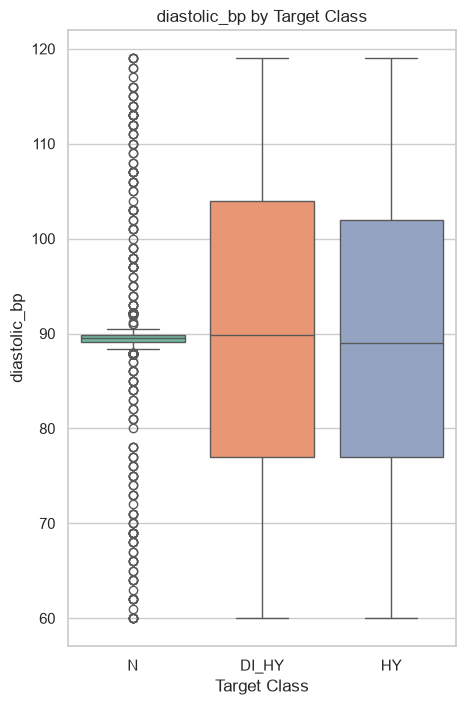

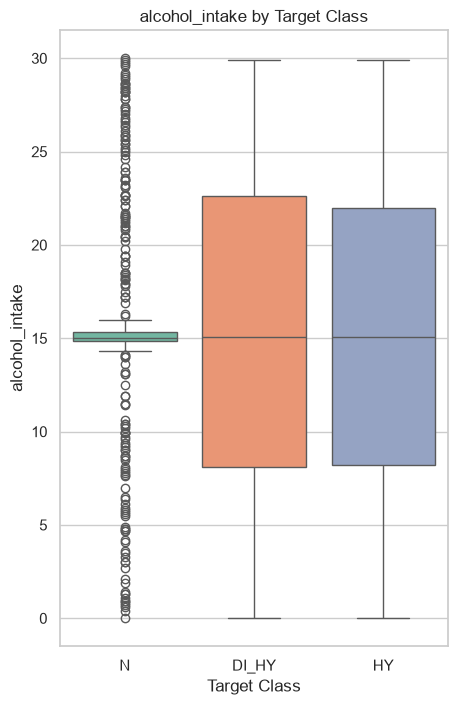

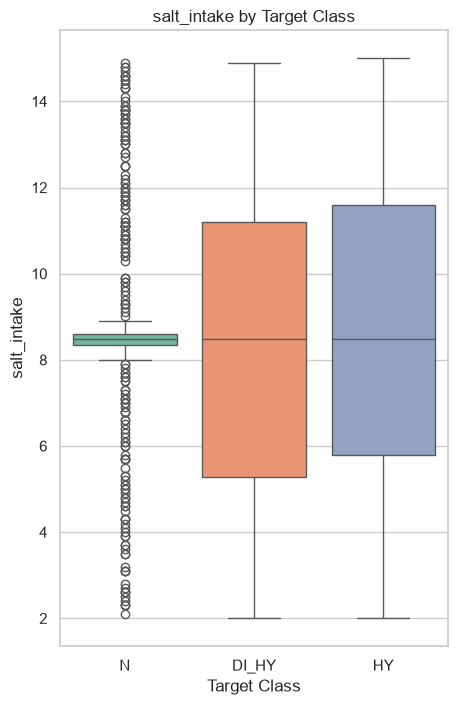

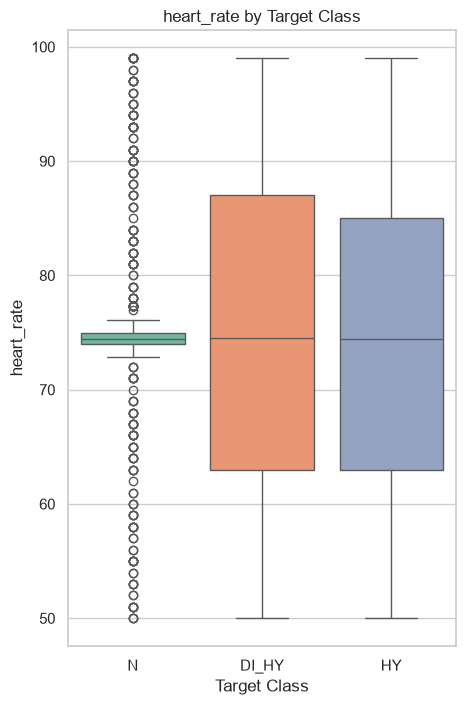

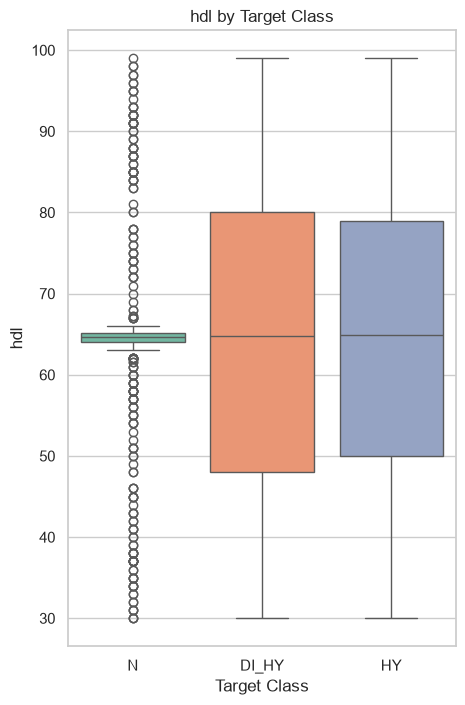

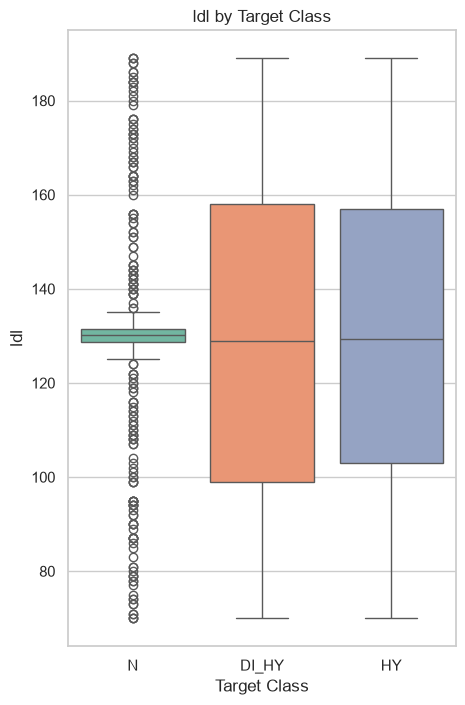

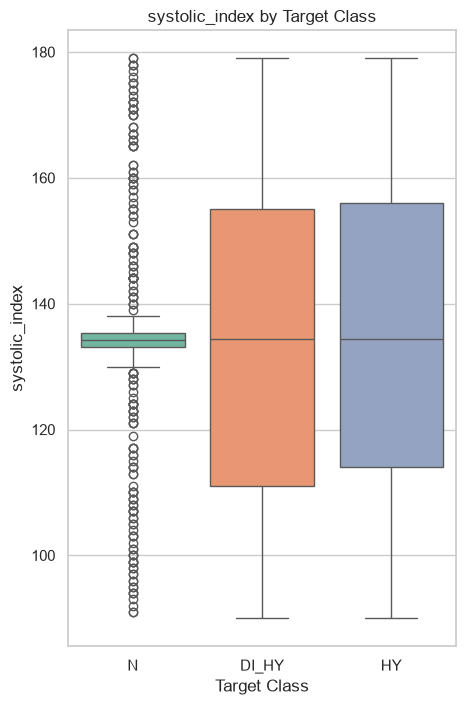

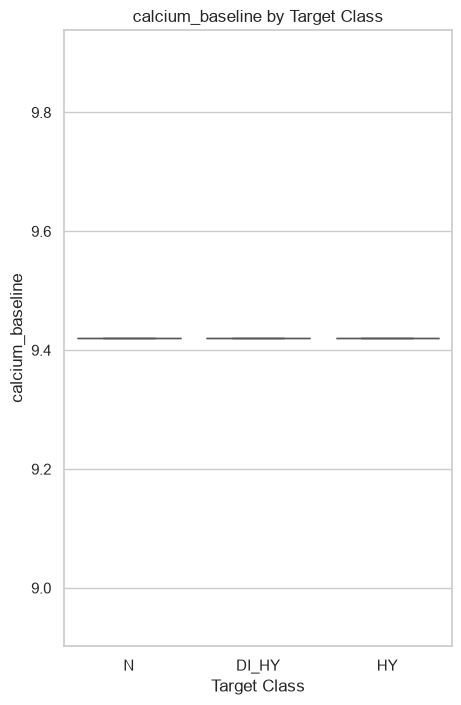

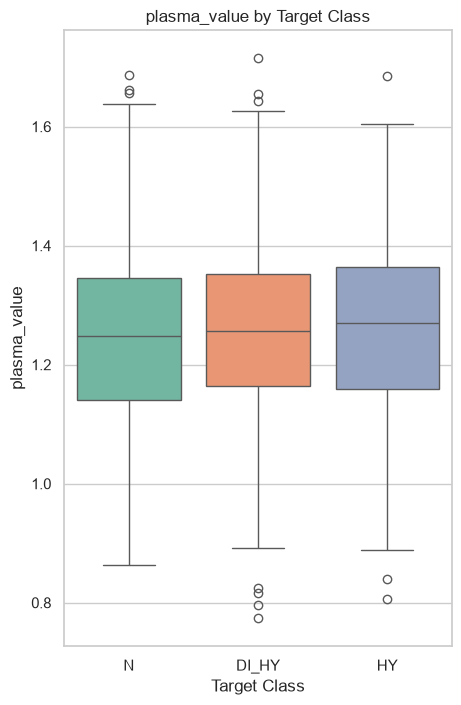

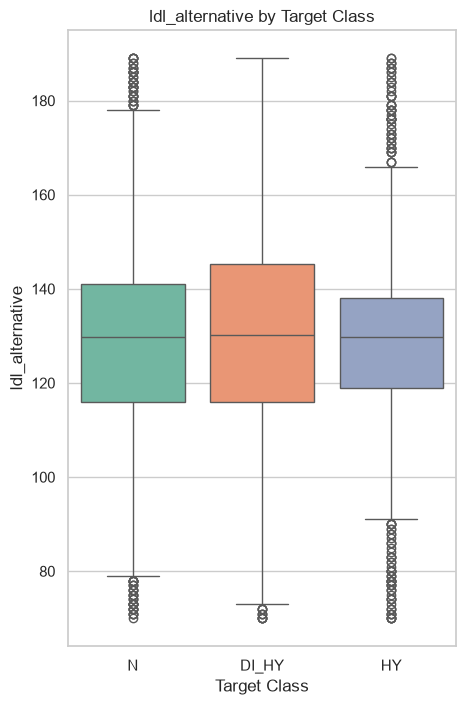

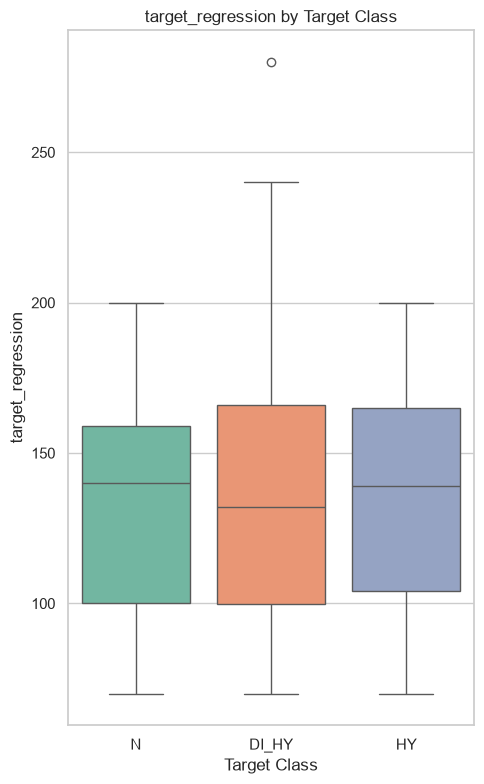

In [19]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Load your dataset
df = pd.read_csv('dataset_grupo_01.csv')

# 2. Select a few key numerical features to visualize against the target class
key_num_cols = ['age', 'bmi', 'HbA1c_level', 'cholesterol', 'sleep_hours', 'triglycerides', 'blood_pressure', 'crp_level', 'homocysteine_level', 'systolic_bp', 'diastolic_bp', 'alcohol_intake', 'salt_intake', 'heart_rate', 'hdl', 'ldl', 'systolic_index', 'calcium_baseline', 'plasma_value', 'ldl_alternative', 'target_regression']

# 3. Create a grid of box plots
plt.figure(figsize=(15, 10))
for i, col in enumerate(key_num_cols, 1):
    plt.figure(figsize=(5, 8))
    sns.boxplot(x='target_class', y=col, data=df, palette='Set2')
    plt.title(f'{col} by Target Class')
    plt.xlabel('Target Class')
    plt.ylabel(col)

plt.tight_layout()
plt.show()

In [20]:
# 2. Select only numerical columns
num_cols = df.select_dtypes(include=['int64', 'float64']).columns.tolist()

# 3. Calculate outlier counts for each numerical feature
outlier_data = []
for col in num_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    
    # Count rows falling outside the 1.5x IQR whiskers
    outlier_count = df[(df[col] < lower_bound) | (df[col] > upper_bound)].shape[0]
    
    outlier_data.append({'Feature': col, 'Outlier Count': outlier_count})

# 4. Display as a clean sorted table
outlier_df = pd.DataFrame(outlier_data).sort_values(by='Outlier Count', ascending=False)
print(outlier_df.to_string(index=False))

           Feature  Outlier Count
        heart_rate            377
      diastolic_bp            329
       systolic_bp            252
    systolic_index            252
               ldl            224
   ldl_alternative            224
homocysteine_level            217
       salt_intake            211
         crp_level            184
    alcohol_intake            178
               hdl            157
    blood_pressure            156
      plasma_value             12
       sleep_hours             12
       HbA1c_level              6
               bmi              5
 target_regression              1
               age              0
       cholesterol              0
    age_normalized              0
     triglycerides              0
  calcium_baseline              0


In [21]:
import pandas as pd
import numpy as np

# 1. Load your dataset
df = pd.read_csv('dataset_grupo_01.csv')

# 2. Select all numerical columns
num_cols = df.select_dtypes(include=['int64', 'float64']).columns.tolist()

summary_list = []
for col in num_cols:
    # Calculate overall median
    median_val = df[col].median()
    
    # Calculate medians grouped by target class to check separation
    medians_by_target = df.groupby('target_class')[col].median().to_dict()
    
    # Calculate IQR and outlier bounds
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    
    # Extract outliers
    outliers = df[(df[col] < lower_bound) | (df[col] > upper_bound)][col]
    outlier_count = len(outliers)
    
    min_outlier = outliers.min() if outlier_count > 0 else np.nan
    max_outlier = outliers.max() if outlier_count > 0 else np.nan
    
    # Append to summary list
    summary_list.append({
        'Feature': col,
        'Overall Median': median_val,
        'Median (N)': medians_by_target.get('N', np.nan),
        'Median (HY)': medians_by_target.get('HY', np.nan),
        'Median (DI_HY)': medians_by_target.get('DI_HY', np.nan),
        'Outlier Count': outlier_count,
        'Min Outlier': min_outlier,
        'Max Outlier': max_outlier
    })

# 3. Convert to DataFrame and display sorted by outlier count
summary_df = pd.DataFrame(summary_list).sort_values(by='Outlier Count', ascending=False)
print(summary_df.to_string(index=False))

# Optional: Export straight to a CSV or Excel table for your report
# summary_df.to_csv('numerical_feature_diagnostics.csv', index=False)

           Feature  Overall Median  Median (N)  Median (HY)  Median (DI_HY)  Outlier Count  Min Outlier  Max Outlier
        heart_rate       74.487247   74.458420    74.437397       74.565645            377    50.000000    99.000000
      diastolic_bp       89.483306   89.504587    89.000000       89.814606            329    60.000000   119.000000
       systolic_bp      134.176874  134.167413   134.435169      134.377104            252    90.000000   179.000000
    systolic_index      134.176874  134.167413   134.435169      134.377104            252    90.000000   179.000000
               ldl      129.983051  130.217467   129.354661      129.000000            224    70.000000   189.000000
   ldl_alternative      129.983051  129.803846   129.803846      130.244654            224    70.000000   189.000000
homocysteine_level       12.504625   12.508636    12.522140       12.416645            217     5.309536    19.959139
       salt_intake        8.477600    8.477600     8.490022     

employment_status  Retired (688, 34.4%)    Employed (650, 32.5%)   1.06
high_ldl_cholesterol     Yes (1013, 50.6%)          No (987, 49.4%)   1.03
gender  2.102194e-01                    3.8
high_ldl_cholesterol  2.559435e-01                    3.6